# 13 · La vigilancia completa: la salud de toda la ciudad

## Pregunta y diseño

El SIVIGILA, el sistema de vigilancia en salud pública, es la fuente externa más abundante del proyecto y la menos aprovechada: se integraron 14 eventos y se habían mirado dos o tres. Este cuaderno trata la salud de toda la ciudad como una variable general, no como casos puntuales, y lo hace cuidando el sobreajuste: son decenas de series y nueve rezagos, y con tantas pruebas el azar produce hallazgos de apariencia convincente.

El cuaderno tiene dos partes. La primera (secciones 1 a 6) mide cada serie de vigilancia contra el **triage total** semanal: inventario, barrido con corrección por pruebas múltiples, confirmación en un año que no se usó para descubrir, un índice de presión epidemiológica, la relación entre geografías y el rezago de publicación. La segunda (secciones 7 a 9) repite la medición con la perspectiva de mecanismos, porque el triage total es el peor blanco posible para un factor que actúa sobre una parte pequeña de los pacientes, en una edad concreta y durante unas semanas: las olas se tratan como episodios, las enfermedades como familias, el efecto se mide por banda de edad y el rezago se recorre semana a semana. La sección 10 reúne las conclusiones y los límites.

## El desenlace

`from desenlace import desenlace_semanal`, columna `y`: triage total por semana epidemiológica, en logaritmo, **sin calendario y sin los cortes de nivel de la red** (Nueva EPS), **con la estacionalidad**. Descubrir: 2022-03 a 2024-12. Confirmar: **2025-01 a 2025-12**, porque los microdatos del SIVIGILA terminan en 2025. Desenlaces secundarios: `y_respiratorio`, `y_infecciosas` y `y_trauma`, construidos con los diagnósticos agregados del perfil del hospital (cuaderno 10), y, en la sección 8, el triage semanal por banda de edad con el mismo tratamiento.

Todo sale de archivos agregados del repositorio. No hay conexión a la base del hospital ni datos de pacientes.

In [1]:
import sys, pathlib, warnings, os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from desenlace import desenlace_semanal
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
DIVERGE = LinearSegmentedColormap.from_list("diverge", [AZUL, "#f4f3f0", ROJO])
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

SES = 170010010301
COVID = ("2020-03-01", "2021-12-31")
DESC = ("2022-03-06", "2024-12-29")          # descubrir (desenlace.py)
CONF = ("2025-01-05", "2025-12-28")          # confirmar: el SIVIGILA termina en 2025
REZ = list(range(0, 9))
q_BH = 0.10
rejilla = pd.date_range("2015-01-04", "2025-12-28", freq="W-SUN")

vig = pd.concat([pd.read_csv(RAIZ / f"calendarios/{n}.csv.gz") for n in ("vigilancia_sivigila", "vigilancia_sivigila_eventos")],
                ignore_index=True)
vig["fecha_inicio_semana"] = pd.to_datetime(vig["fecha_inicio_semana"])
PV = vig.pivot_table(index="fecha_inicio_semana", columns=["ambito", "evento", "variable"], values="valor", aggfunc="sum")
inst = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_instituciones.csv.gz", parse_dates=["fecha_inicio_semana"])
# Error de la fuente (sección 1): la SE53 de 2025 del 998 multiplica por ~7 la EDA de Manizales en todas las bandas a la vez
SE53 = pd.Timestamp("2025-12-28")
cols998 = [c for c in PV.columns if c[1] == 998 and c[0] in ("manizales", "caldas") and c[2].startswith("casos_eda")]
print("998, SE53 de 2025 antes de anular:", {f"{c[0]} {c[2]}": PV.loc[SE53, c] for c in cols998 if c[2] == "casos_eda_total"})
PV.loc[SE53, cols998] = np.nan
def serie(ambito, evento, variable):
    col = (ambito, evento, variable)
    return PV[col].reindex(rejilla) if col in PV.columns else None

Y = desenlace_semanal()
print("vigilancia:", PV.index.min().date(), "a", PV.index.max().date(), "|", PV.shape[1], "columnas")
print("desenlace:", Y.index.min().date(), "a", Y.index.max().date(), "| columnas:", [c for c in Y.columns if c.startswith("y")])

998, SE53 de 2025 antes de anular: {'caldas casos_eda_total': 2640.0, 'manizales casos_eda_total': 2495.0}


vigilancia: 2011-01-02 a 2025-12-28 | 464 columnas
desenlace: 2022-03-06 a 2026-09-13 | columnas: ['y', 'y_respiratorio', 'y_infecciosas', 'y_trauma']


---
# 1. Inventario de las series de vigilancia

Hay tres niveles geográficos (Manizales, Caldas y Colombia) y tres fuentes:
- **995, IRA colectiva:** consultas por infección respiratoria aguda por banda de edad, hospitalización por IRAG, UCI y muertes. Un registro por institución y semana, con denominador.
- **998, EDA colectiva:** casos de enfermedad diarreica aguda por banda de edad y hospitalizados. Sin denominador.
- **Eventos individuales:** 14 integrados, más 3 marcadores (pólvora, brotes de enfermedades transmitidas por alimentos e IRAG inusitado).

A estas se añade una cuarta, construida aquí: la **IRA de Manizales sin el SES** (institución `170010010301`), a partir del archivo por institución, porque el SES es el propio hospital.

**Conteos, no proporciones.** El denominador del 995 crece por escalones (+60 % en 2021 y +35 % en 2024, según la auditoría de la fuente), de modo que la proporción de IRA no es comparable entre años. Se usa el conteo y el nivel de cada año se quita en la anomalía.

In [2]:
BANDAS_IRA = ["0_4", "5_19", "20_39", "40_59", "60_mas"]
BANDAS_EDA = ["0_4", "5_14", "15_44", "45_64", "65_mas"]
FUGA = {300, 356, 365, 370, 549, 875}         # personas que pueden ser las mismas que llegan al triage
NOMBRE_EV = {300: "agresiones por animales", 875: "violencias de género e intrafamiliar", 356: "intento de suicidio",
             365: "intoxicaciones (365)", 370: "intoxicación por fármacos", 549: "morbilidad materna extrema",
             831: "varicela", 155: "cáncer de mama y cuello", 850: "VIH / sida", 813: "tuberculosis (813)",
             820: "tuberculosis pulmonar", 113: "desnutrición aguda < 5", 620: "parotiditis"}
FAMILIA_EV = {300: "lesiones", 875: "violencia", 356: "salud mental", 365: "intoxicaciones", 370: "intoxicaciones",
              549: "materno", 831: "contagio", 155: "crónico", 850: "crónico", 813: "crónico", 820: "crónico",
              113: "nutrición", 620: "contagio"}
catalogo = []
for amb in ["manizales", "caldas", "colombia"]:
    var_ev = "casos_total" if amb == "colombia" else "casos_ocurrencia"
    catalogo += [(amb, "IRA total", 995, "consultas_ira_total", "respiratorio")]
    catalogo += [(amb, f"IRA {b.replace('_', '-').replace('-mas', '+')}", 995, f"consultas_ira_{b}", "respiratorio") for b in BANDAS_IRA]
    catalogo += [(amb, "IRAG hospitalización", 995, "hospitalizaciones_irag_total", "respiratorio grave"),
                 (amb, "IRAG UCI", 995, "uci_irag_total", "respiratorio grave"),
                 (amb, "IRAG muertes", 995, "muertes_irag_total", "respiratorio grave")]
    catalogo += [(amb, "EDA total", 998, "casos_eda_total", "gastro")]
    catalogo += [(amb, f"EDA {b.replace('_', '-').replace('-mas', '+')}", 998, f"casos_eda_{b}", "gastro") for b in BANDAS_EDA]
    catalogo += [(amb, "EDA hospitalizados", 998, "casos_eda_hospitalizados", "gastro")]
    catalogo += [(amb, NOMBRE_EV[e], e, var_ev, FAMILIA_EV[e]) for e in NOMBRE_EV]
S = {}                                      # (ambito, nombre) -> serie semanal de conteos
meta = {}
for amb, nom, ev, var, fam in catalogo:
    s = serie(amb, ev, var)
    if s is not None:
        S[(amb, nom)] = s; meta[(amb, nom)] = {"fuente": ev, "familia": fam}
ira_sin_ses = inst[inst.cod_upgd.ne(SES)].groupby("fecha_inicio_semana")["consultas_ira"].sum().reindex(rejilla)
S[("manizales", "IRA total sin SES")] = ira_sin_ses; meta[("manizales", "IRA total sin SES")] = {"fuente": 995, "familia": "respiratorio"}
ses_anual = inst[inst.cod_upgd.eq(SES)].groupby(inst.fecha_inicio_semana.dt.year)["consultas_ira"].sum()
tot_anual = inst.groupby(inst.fecha_inicio_semana.dt.year)["consultas_ira"].sum()
print("IRA notificada por el SES al 995, % de la IRA de Manizales:",
      (100 * ses_anual.reindex(tot_anual.index).fillna(0) / tot_anual).loc[2015:].round(2).to_dict())
print("r semanal IRA total vs IRA sin SES, 2015-2025:", round(S[("manizales", "IRA total")].corr(ira_sin_ses), 4))

# Semanas imposibles: más de 3 veces, o menos de un tercio, de la mediana de las 9 semanas vecinas (series con mediana >= 20)
marcas = []
for (amb, nom), s in S.items():
    s = s.loc["2015":]
    if amb == "colombia" or s.median() < 20: continue
    med = s.rolling(9, center=True, min_periods=5).median(); r = s / med
    marcas += [{"ámbito": amb, "serie": nom, "semana": str(f.date()), "valor": int(s[f]), "mediana vecina": int(med[f])}
               for f in r[(r > 3) | (r < 1 / 3)].index]
marcas = pd.DataFrame(marcas)
print(f"Semanas marcadas (Manizales y Caldas, 2015-2025, ya sin la SE53 del 998): {len(marcas)}; "
      f"en 2022-2025: {int((marcas.semana >= '2022').sum())}")
display(marcas[marcas.semana >= "2022"])

filas = []
for (amb, nom), s in S.items():
    x = s.dropna(); x = x[x.index >= "2015-01-01"]
    d, c = s.loc[DESC[0]:DESC[1]], s.loc[CONF[0]:CONF[1]]
    filas.append({"ámbito": amb, "serie": nom, "fuente": meta[(amb, nom)]["fuente"], "familia": meta[(amb, nom)]["familia"],
                  "desde": x.index.min().year if len(x) else None,
                  "media/sem 2022-24": round(d.mean(), 1), "media/sem 2025": round(c.mean(), 1),
                  "% semanas en 0 (2022-25)": round(100 * (pd.concat([d, c]) == 0).mean()),
                  "fuga posible": "sí" if meta[(amb, nom)]["fuente"] in FUGA else ""})
INV = pd.DataFrame(filas)
print("Parte de Manizales dentro de Caldas, conteos 2022-2025 (%):",
      {n: round(100 * S[("manizales", n)].loc["2022":].sum() / S[("caldas", n)].loc["2022":].sum()) for n in ["IRA total", "EDA total", "EDA hospitalizados"]})
print(f"{len(INV)} series: {INV.ámbito.value_counts().to_dict()}")
INV[INV.ámbito.eq("manizales")].set_index("serie").drop(columns="ámbito")

IRA notificada por el SES al 995, % de la IRA de Manizales:

 {2015: 0.22, 2016: 0.06, 2017: 0.0, 2018: 0.0, 2019: 0.0, 2020: 0.06, 2021: 0.07, 2022: 0.0, 2023: 0.05, 2024: 0.17, 2025: 0.0}
r semanal IRA total vs IRA sin SES, 2015-2025: 1.0


Semanas marcadas (Manizales y Caldas, 2015-2025, ya sin la SE53 del 998): 39; en 2022-2025: 9


,ámbito,serie,semana,valor,mediana vecina
9,manizales,EDA 5-14,2022-06-26,7,23
29,caldas,EDA hospitalizados,2023-04-02,75,22
30,caldas,EDA hospitalizados,2023-05-07,84,27
31,caldas,EDA hospitalizados,2023-12-24,10,42
32,caldas,EDA hospitalizados,2024-04-14,148,37
33,caldas,EDA hospitalizados,2024-04-21,237,37
34,caldas,EDA hospitalizados,2024-04-28,254,37
35,caldas,EDA hospitalizados,2024-10-13,9,28
36,caldas,EDA hospitalizados,2025-05-25,198,41


Parte de Manizales dentro de Caldas, conteos 2022-2025 (%): {'IRA total': 68, 'EDA total': 65, 'EDA hospitalizados': 70}
88 series: {'manizales': 30, 'caldas': 29, 'colombia': 29}


,fuente,familia,desde,media/sem 2022-24,media/sem 2025,% semanas en 0 (2022-25),fuga posible
serie,,,,,,,
IRA total,995,respiratorio,2015,1180.9,1274.9,0,
IRA 0-4,995,respiratorio,2015,167.6,143.9,0,
IRA 5-19,995,respiratorio,2015,184.6,171.3,0,
IRA 20-39,995,respiratorio,2015,370.1,376.6,0,
IRA 40-59,995,respiratorio,2015,231.9,279.2,0,
IRA 60+,995,respiratorio,2015,226.8,303.9,0,
IRAG hospitalización,995,respiratorio grave,2015,39.3,37.5,0,
IRAG UCI,995,respiratorio grave,2015,13.8,19.8,0,
IRAG muertes,995,respiratorio grave,2015,4.8,1.9,10,


## Lectura del inventario

Hay **88 series semanales**: 30 de Manizales, 29 de Caldas y 29 de Colombia. Por fuente, 9 son del 995 (IRA total, cinco bandas de edad, hospitalización, UCI y muertes por IRAG), 7 del 998 (EDA total, cinco bandas y hospitalizados) y 13 son eventos individuales. En Manizales se añade la IRA sin el SES.

- **Quitar el SES no cambia nada.** El SES notifica al 995 entre el 0 % y el 0,22 % de la IRA de Manizales desde 2015 (0 % en 2025), y la IRA con y sin él correlaciona 1,0 semana a semana. El hospital casi no notifica su IRA a la vigilancia colectiva, de modo que la IRA de la ciudad **no contiene mecánicamente** al hospital. La serie se deja en el barrido por transparencia, aunque es la misma.
- **Volumen.** La IRA ronda las 1.181 consultas por semana en 2022-2024 (1.275 en 2025) y la EDA unos 398 casos (365 en 2025). Entre los eventos, las agresiones por animales (~25) y las violencias (~24) son los de mayor volumen; la desnutrición aguda (32 % de las semanas en cero) y la parotiditis (40 %) son casi vacías.
- **Error de la fuente, anulado.** La SE53 de 2025 del 998 trae 2.495 casos de EDA en Manizales y 2.640 en Caldas, unas siete veces una semana normal, con todas las bandas de edad a la vez y sin reflejo en Colombia. Se trata como hueco. La corrección se aplica aquí en memoria; el archivo de origen conserva el valor.
- **Otras semanas atípicas** (más de tres veces o menos de un tercio de la mediana de las 9 semanas vecinas): 9 en 2022-2025, casi todas en la **EDA hospitalizada de Caldas**, con brotes de 148 a 254 hospitalizados por semana en abril de 2024 frente a una mediana de 37. Como la serie de Manizales ronda los 26, esos brotes son de otros municipios. Se conservan, porque pueden ser reales.
- **Fuera del barrido** quedan la COVID (346), que solo existe desde 2024 y no permite estimar una estación, y los tres marcadores, que son semanas sueltas y no series. El evento 348 absorbió además COVID en 2022-2023.
- **Seis series pueden contener a las mismas personas que llegan al triage** (columna «fuga posible»): agresiones por animales, violencias, intento de suicidio, intoxicaciones (365 y 370) y morbilidad materna extrema.

**Límite.** Colombia solo entra en la sección 5; el barrido es de Manizales y Caldas. Caldas **incluye** a Manizales.

## Volumen de los eventos individuales

El número de casos de cada evento decide si admite una serie semanal. La tabla reúne los eventos que más se citan, con los casos por año del censo de la fuente y el promedio semanal de la base 2023-2025.

In [3]:
censo = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_eventos_censo.csv")
elegidos = {300: "300 agresiones por animales", 875: "875 violencias de género e intrafamiliar", 356: "356 intento de suicidio",
            365: "365 intoxicaciones", 831: "831 varicela", 210: "210 dengue"}
cols_c = ["casos_2022", "casos_2023", "casos_2024", "casos_2025", "media_semanal_base", "estado"]
vol = censo[censo.evento.isin(elegidos)].set_index("evento").loc[list(elegidos), cols_c]
vol.index = [elegidos[e] for e in vol.index]
vol.columns = ["2022", "2023", "2024", "2025", "casos/semana (2023-25)", "estado"]
vol

,2022,2023,2024,2025,casos/semana (2023-25),estado
300 agresiones por animales,1163.0,1364.0,1345.0,1555.0,27.159,integrada
875 violencias de género e intrafamiliar,1060.0,1255.0,1308.0,1332.0,24.809,integrada
356 intento de suicidio,618.0,703.0,596.0,566.0,11.879,integrada
365 intoxicaciones,447.0,548.0,510.0,444.0,9.567,integrada
831 varicela,224.0,222.0,211.0,237.0,4.268,integrada
210 dengue,NaN,5.0,84.0,4.0,0.592,volumen insuficiente


Las agresiones por animales (código 300) y las violencias (875) son los eventos con más casos, de 1.060 a 1.555 por año, es decir, de 25 a 27 por semana. El intento de suicidio (356) ronda las 12 por semana, las intoxicaciones (365) las 10 y la varicela (831) las 4. Son conteos bajos: con 4 casos por semana el ruido de Poisson es de ±50 %, y por eso estas series entran agrupadas en familias y no una a una.

El **dengue (210) casi no existe en Manizales**: 5 casos en 2023, 84 en 2024 y 4 en 2025, 0,59 por semana. Su volumen no permite una serie y el evento queda como no integrable. Que 2024 concentre 84 casos coincide con el año epidémico del dengue en el país, pero no se puede afirmar que fueran casos autóctonos de una ciudad a 2.150 m de altitud.

## Los escalones, en conteos

Se divide el conteo anual de cada serie de Manizales entre su media de 2015-2019. Así se comparan los años sin pasar por la proporción, que arrastra el escalón del denominador. Se añade el número de instituciones que notifican al 995 y al 998, que es la **cobertura**.

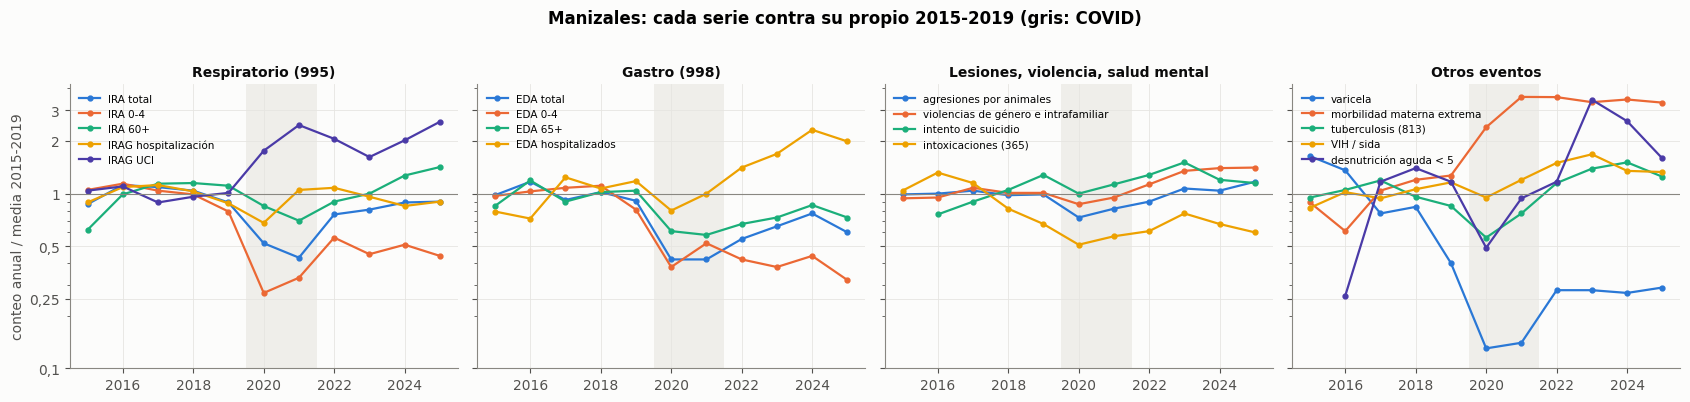

,instituciones 995,instituciones 998,IRA total,IRA 0-4,IRAG hospitalización,IRAG UCI,EDA total,EDA hospitalizados,intento de suicidio,violencias de género e intrafamiliar,intoxicaciones (365),morbilidad materna extrema,varicela,desnutrición aguda < 5
2015,37.2,33.6,0.87,1.05,0.89,1.04,0.98,0.79,NaN,0.94,1.04,0.89,1.64,NaN
2016,55.9,33.4,1.12,1.14,1.09,1.10,1.17,0.72,0.76,0.95,1.32,0.61,1.36,0.26
2017,50.2,32.1,1.09,1.04,1.12,0.89,0.92,1.24,0.90,1.08,1.15,1.04,0.77,1.17
2018,48.5,29.5,1.04,0.99,1.03,0.96,1.02,1.07,1.05,1.01,0.82,1.20,0.84,1.40
2019,44.2,26.8,0.89,0.79,0.88,1.01,0.91,1.18,1.28,1.01,0.67,1.27,0.40,1.17
2020,34.2,21.1,0.52,0.27,0.68,1.76,0.42,0.80,1.00,0.87,0.51,2.40,0.13,0.49
2021,36.8,22.1,0.43,0.33,1.05,2.47,0.42,1.00,1.13,0.95,0.57,3.58,0.14,0.94
2022,38.3,21.0,0.76,0.56,1.08,2.06,0.55,1.41,1.28,1.13,0.61,3.57,0.28,1.17
2023,40.5,21.0,0.81,0.45,0.96,1.62,0.65,1.69,1.51,1.35,0.77,3.34,0.28,3.45
2024,50.3,26.0,0.89,0.51,0.85,2.02,0.77,2.32,1.20,1.40,0.67,3.46,0.27,2.60


In [4]:
anual = pd.DataFrame({nom: s.groupby(s.index.year).sum(min_count=40) for (amb, nom), s in S.items() if amb == "manizales"}).loc[2015:2025]
cobertura = pd.DataFrame({f"instituciones {e}": serie("manizales", e, "n_instituciones_notificando").groupby(rejilla.year).mean()
                          for e in (995, 998)}).loc[2015:2025].round(1)
indice = (anual / anual.loc[2015:2019].mean()).round(2)
grupos_fig = [("Respiratorio (995)", ["IRA total", "IRA 0-4", "IRA 60+", "IRAG hospitalización", "IRAG UCI"]),
              ("Gastro (998)", ["EDA total", "EDA 0-4", "EDA 65+", "EDA hospitalizados"]),
              ("Lesiones, violencia, salud mental", ["agresiones por animales", "violencias de género e intrafamiliar", "intento de suicidio", "intoxicaciones (365)"]),
              ("Otros eventos", ["varicela", "morbilidad materna extrema", "tuberculosis (813)", "VIH / sida", "desnutrición aguda < 5"])]
colores = [AZUL, NARANJA, AQUA, AMARILLO, VIOLETA]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
for ax, (tit, cols) in zip(axes, grupos_fig):
    for c, col in zip(cols, colores):
        ax.plot(indice.index, indice[c], marker="o", ms=3.5, lw=1.6, color=col, label=c)
    ax.axhline(1, color=MUDO, lw=.8); ax.axvspan(2019.5, 2021.5, color="#efeeea", lw=0)
    ax.set_title(tit, fontsize=10); ax.legend(fontsize=7.5, loc="upper left")
axes[0].set_ylabel("conteo anual / media 2015-2019"); axes[0].set_yscale("log")
axes[0].set_yticks([0.1, 0.25, 0.5, 1, 2, 3]); axes[0].set_yticklabels(["0,1", "0,25", "0,5", "1", "2", "3"])
plt.suptitle("Manizales: cada serie contra su propio 2015-2019 (gris: COVID)", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()
pd.concat([cobertura, indice[["IRA total", "IRA 0-4", "IRAG hospitalización", "IRAG UCI", "EDA total", "EDA hospitalizados", "intento de suicidio",
                              "violencias de género e intrafamiliar", "intoxicaciones (365)", "morbilidad materna extrema",
                              "varicela", "desnutrición aguda < 5"]]], axis=1)

## Lectura de los escalones

**Casi todas las series tienen escalones, y varios no son epidemiología.** Conteo anual sobre la media de 2015-2019:

| Serie | 2019 | 2022 | 2024 | 2025 | Qué es |
|---|---|---|---|---|---|
| Instituciones que notifican el 995 | 44,2 | 38,3 | 50,3 | 53,6 | **Cobertura**: sube un tercio entre 2022 y 2025 |
| Instituciones que notifican el 998 | 26,8 | 21,0 | 26,0 | 27,8 | Cae en la pandemia y no vuelve a 2015-2017 (33) |
| IRA total | 0,89 | 0,76 | 0,89 | 0,90 | No vuelve al nivel prepandemia |
| IRA 0-4 | 0,79 | 0,56 | 0,51 | **0,44** | La IRA infantil está a menos de la mitad |
| IRAG UCI | 1,01 | 2,06 | 2,02 | **2,58** | Más que duplicada desde 2020 |
| EDA total | 0,91 | 0,55 | 0,77 | 0,60 | Caída desde 2020 sin explicación comprobada |
| **EDA hospitalizados** | 1,18 | 1,41 | **2,32** | 1,99 | **Sube mientras la EDA total baja**: más hospitalización por caso o cambio de registro [I] |
| Morbilidad materna extrema | 1,27 | 3,57 | 3,46 | 3,32 | Escalón de ×3 en 2020-2021, de definición |
| Varicela | 0,40 | 0,28 | 0,27 | 0,29 | Caída por vacunación y pandemia |
| Violencias | 1,01 | 1,13 | 1,40 | 1,41 | Sube un 40 % |

Consecuencias:
- **Ninguna proporción ni ningún nivel se compara entre años.** Por eso el barrido usa la anomalía, con el nivel de cada año quitado.
- La media anual no quita los escalones **dentro** de un año. El de EDA hospitalizados (2022 a 2024) es el que más pesa y reaparece en la sección 4b.
- La IRA infantil de la ciudad está hoy a menos de la mitad de 2015-2019. Cualquier «temporada respiratoria» actual es más baja que las de antes de la pandemia.

## Construcción de la anomalía

Para cada serie se toma `log(1 + conteo)`, se resta la **forma estacional típica** (3 armónicos anuales, ajustados en 2015-2019 y 2022-2024, **nunca con 2025**) y se resta la **media de cada año**. Lo que queda indica cuánto se aparta cada semana de lo normal para esa época y ese año, de modo que ni el escalón de cobertura ni la estación típica cuentan como señal.

**Límite.** La media del año se calcula con el año entero. Para operar habría que sustituirla por una media móvil hacia atrás, lo que se mide en la sección 6 y se usa desde la sección 7.

Amplitud de la forma estacional típica (pico/valle - 1, %), Manizales:
{'IRA total': 30, 'IRA 0-4': 63, 'IRAG hospitalización': 62, 'EDA total': 52, 'intento de suicidio': 43, 'varicela': 58}


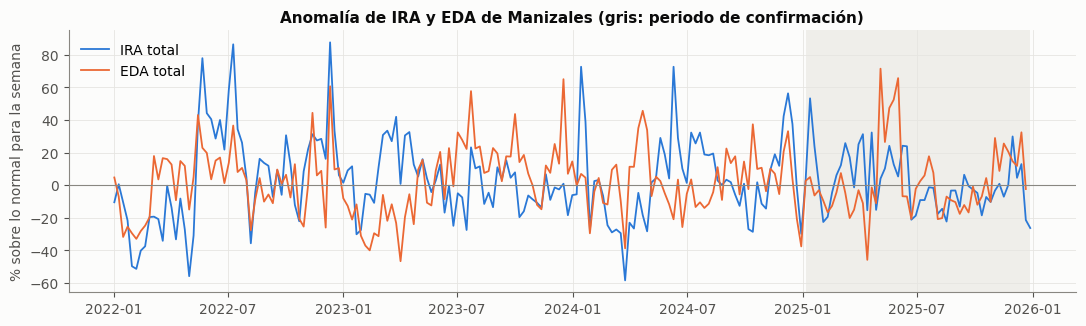

In [5]:
t_ano = rejilla.dayofyear.values / 365.25
FOURIER = pd.DataFrame({f"{n}{k}": f(2 * np.pi * k * t_ano) for k in (1, 2, 3) for n, f in (("s", np.sin), ("c", np.cos))}, index=rejilla)
FOURIER.insert(0, "c", 1.0)
en_ajuste = (~rejilla.to_series().between(*COVID)).values & (rejilla <= "2024-12-31")
def anomalia(s, devolver_estacion=False):
    l = np.log1p(s.astype(float).reindex(rejilla))
    lc = l - l.groupby(l.index.year).transform("mean")
    ok = lc.notna().values & en_ajuste
    b, *_ = np.linalg.lstsq(FOURIER.values[ok], lc.values[ok], rcond=None)
    est = pd.Series(FOURIER.values @ b, index=rejilla)
    r = l - est
    r = r - r.groupby(r.index.year).transform("mean")
    return (r, est) if devolver_estacion else r
A = {k: anomalia(s) for k, s in S.items()}
amplitud = {k[1]: round(100 * (np.exp(anomalia(s, True)[1].max() - anomalia(s, True)[1].min()) - 1)) for k, s in S.items() if k[0] == "manizales"}
print("Amplitud de la forma estacional típica (pico/valle - 1, %), Manizales:")
print({k: amplitud[k] for k in ["IRA total", "IRA 0-4", "IRAG hospitalización", "EDA total", "intento de suicidio", "varicela"]})
fig, ax = plt.subplots(figsize=(13, 3.4))
for (k, col) in [(("manizales", "IRA total"), AZUL), (("manizales", "EDA total"), NARANJA)]:
    a = A[k].loc["2022":"2025"]
    ax.plot(a.index, 100 * (np.exp(a) - 1), color=col, lw=1.3, label=k[1])
ax.axhline(0, color=MUDO, lw=.8); ax.axvspan(pd.Timestamp(CONF[0]), pd.Timestamp(CONF[1]), color="#efeeea", lw=0)
ax.set_ylabel("% sobre lo normal para la semana"); ax.legend()
ax.set_title("Anomalía de IRA y EDA de Manizales (gris: periodo de confirmación)"); plt.show()

## Lectura de la anomalía

La forma estacional típica es grande: de valle a pico, **+30 %** en la IRA total, **+63 %** en la IRA 0-4, **+62 %** en la hospitalización por IRAG, **+52 %** en la EDA, **+43 %** en el intento de suicidio y **+58 %** en la varicela. Todo eso sale de la anomalía, y queda cuánto se aparta cada semana de lo normal para esa época.

En la figura, 2022 es el año más movido de la IRA, con semanas por encima de +50 % y otras cerca de −50 % de lo normal. Desde 2023 las dos series oscilan en una banda más estrecha.

**Límite.** Tres armónicos describen una forma suave. Si la estación de los años recientes difiere de la de 2015-2024, parte de esa diferencia queda en la anomalía, lo que resulta decisivo en la sección 4b.

---
# 2. Barrido de cada serie de Manizales y Caldas contra el triage total

Diseño fijado antes de mirar los resultados: cada serie en anomalía, con rezagos de 0 a 8 semanas, contra `y` (triage total semanal, en logaritmo, sin calendario y sin los cortes de la red, **con** estacionalidad), en el periodo de **descubrir** (2022-03 a 2024-12).

- Se ajusta una regresión por serie y rezago, `y_t = a + b · x_{t−k}`, con `x` en desviaciones típicas (de descubrir) y **errores HAC** (Newey-West, 4 rezagos), porque ambas series tienen autocorrelación.
- `100·b` equivale al % de triage por desviación típica de la serie.
- **Benjamini-Hochberg, q = 0,10, sobre toda la familia:** las dos geografías, todas las series y los 9 rezagos, incluido el 0.

**Aviso de fuga.** Intento de suicidio, violencias, intoxicaciones, agresiones por animales y morbilidad materna son **personas** que pueden ser las mismas que llegan al triage: con rezago 0 forman parte del desenlace. Además, el rezago 0 de cualquier serie no está disponible a tiempo para pronosticar. Por ambas razones, **el rezago 0 entra en la familia de BH (la hace más exigente) pero no cuenta como hallazgo.** Solo cuentan los rezagos de 1 en adelante.

**Criterio de confirmación, fijado antes de mirar 2025:** mismo rezago, mismo signo y p unilateral HAC < 0,05 en 2025-01 a 2025-12 (52 semanas). Todo lo demás es «no confirmado».

In [6]:
SD_DESC = {}
def ajuste(y, x, k, periodo, sd=None):
    d = pd.DataFrame({"y": y, "x": x.shift(k)}).loc[periodo[0]:periodo[1]].dropna()
    xs = d.x / (sd if sd else d.x.std())
    m = sm.OLS(d.y, sm.add_constant(xs)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    return m.params.iloc[1], m.bse.iloc[1], m.pvalues.iloc[1], len(d), d.x.std()
yv = Y["y"].reindex(pd.date_range(rejilla[0], Y.index.max(), freq="W-SUN"))
def sin_estacion(y):
    """El desenlace sin su propia forma estacional (3 armónicos ajustados solo en descubrir). Se usa en la sección 4b."""
    t = y.index.dayofyear.values / 365.25
    F = np.column_stack([np.ones(len(y))] + [f(2 * np.pi * k * t) for k in (1, 2, 3) for f in (np.sin, np.cos)])
    ok = (y.notna() & (y.index >= DESC[0]) & (y.index <= DESC[1])).values
    b, *_ = np.linalg.lstsq(F[ok], y.values[ok], rcond=None)
    return y - F @ b
yv_des = sin_estacion(yv)
filas = []
for (amb, nom), a in A.items():
    if amb == "colombia": continue
    a = a.reindex(yv.index)
    for k in REZ:
        b, se, p, n, sd = ajuste(yv, a, k, DESC)
        filas.append({"ámbito": amb, "serie": nom, "fuente": meta[(amb, nom)]["fuente"], "familia": meta[(amb, nom)]["familia"],
                      "rezago": k, "efecto %": 100 * b, "ee": 100 * se, "p": p, "n": n, "sd_desc": sd})
B = pd.DataFrame(filas)
B["q"] = multipletests(B.p, method="fdr_bh")[1]
B["sobrevive BH"] = B.q < q_BH
B["cuenta"] = B["sobrevive BH"] & B.rezago.ge(1)
print(f"Desviación típica del desenlace y en descubrir: {100 * yv.loc[DESC[0]:DESC[1]].std():.1f} % (log)")
print(f"Pruebas: {len(B)} = {B.groupby('ámbito').serie.nunique().to_dict()} series x {len(REZ)} rezagos")
print(f"Sobreviven a BH (q < {q_BH}): {B['sobrevive BH'].sum()} | de ellas con rezago >= 1: {B.cuenta.sum()} "
      f"| series distintas con rezago >= 1: {B[B.cuenta].groupby(['ámbito', 'serie']).ngroups}")
print(f"p < 0,05 sin corregir: {(B.p < .05).sum()} de {len(B)} (por azar se esperarían {0.05 * len(B):.0f})")

Desviación típica del desenlace y en descubrir: 6.1 % (log)
Pruebas: 531 = {'caldas': 29, 'manizales': 30} series x 9 rezagos
Sobreviven a BH (q < 0.1): 13 | de ellas con rezago >= 1: 10 | series distintas con rezago >= 1: 5
p < 0,05 sin corregir: 63 de 531 (por azar se esperarían 27)


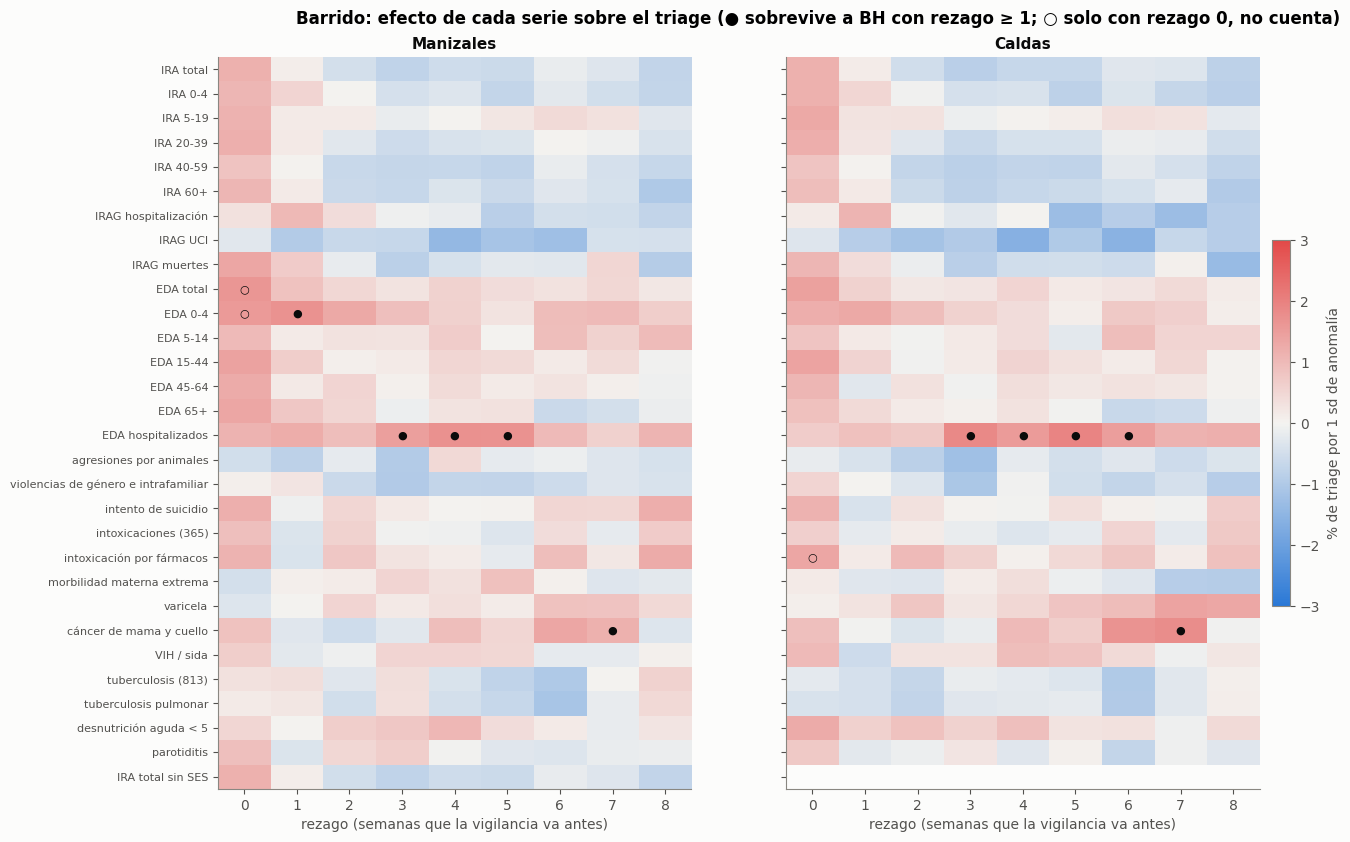

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9.5), sharey=True)
orden = [n for (a, n) in A if a == "manizales"]
for ax, amb in zip(axes, ["manizales", "caldas"]):
    M = B[B.ámbito.eq(amb)].pivot(index="serie", columns="rezago", values="efecto %").reindex(orden)
    Q = B[B.ámbito.eq(amb)].pivot(index="serie", columns="rezago", values="sobrevive BH").reindex(orden)
    im = ax.imshow(M.values, cmap=DIVERGE, vmin=-3, vmax=3, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if Q.values[i, j] == True:
                ax.text(j, i, "●" if j >= 1 else "○", ha="center", va="center", fontsize=8, color=TINTA)
    ax.set_xticks(range(len(REZ)), REZ); ax.set_yticks(range(len(orden)), orden, fontsize=8)
    ax.set_xlabel("rezago (semanas que la vigilancia va antes)"); ax.set_title(amb.capitalize()); ax.grid(False)
cb = fig.colorbar(im, ax=axes, shrink=.5, pad=.01); cb.set_label("% de triage por 1 sd de anomalía")
plt.suptitle("Barrido: efecto de cada serie sobre el triage (● sobrevive a BH con rezago ≥ 1; ○ solo con rezago 0, no cuenta)",
             fontweight="bold", y=.93)
plt.show()

In [8]:
SOB = B[B.cuenta].copy()
def confirmar(r):
    x = A[(r.ámbito, r.serie)].reindex(yv.index)
    b, se, p2, n, _ = ajuste(yv, x, r.rezago, CONF, sd=r.sd_desc)
    p1 = p2 / 2 if np.sign(b) == np.sign(r["efecto %"]) else 1 - p2 / 2
    return pd.Series({"efecto % 2025": 100 * b, "p unilateral 2025": p1, "n 2025": n,
                      "mismo signo": np.sign(b) == np.sign(r["efecto %"]), "confirmada": (np.sign(b) == np.sign(r["efecto %"])) and p1 < .05})
if len(SOB):
    SOB = pd.concat([SOB, SOB.apply(confirmar, axis=1)], axis=1)
    tabla = SOB[["ámbito", "serie", "familia", "rezago", "efecto %", "q", "efecto % 2025", "p unilateral 2025", "mismo signo", "confirmada"]]
    print(f"Sobreviven con rezago >= 1: {len(SOB)} pruebas | mismo signo en 2025: {int(SOB['mismo signo'].sum())} "
          f"| confirmadas: {int(SOB.confirmada.sum())}")
    display(tabla.sort_values(["confirmada", "q"], ascending=[False, True]).round(3).reset_index(drop=True))
# El rezago 0 que sobrevive, para ver qué se descartó por fuga o por no estar a tiempo
B[B["sobrevive BH"] & B.rezago.eq(0)][["ámbito", "serie", "efecto %", "q"]].round(3)

Sobreviven con rezago >= 1: 10 pruebas | mismo signo en 2025: 10 | confirmadas: 3


,ámbito,serie,familia,rezago,efecto %,q,efecto % 2025,p unilateral 2025,mismo signo,confirmada
0,caldas,EDA hospitalizados,gastro,5,1.936,0.006,1.616,0.027,True,True
1,caldas,EDA hospitalizados,gastro,4,1.533,0.057,1.955,0.014,True,True
2,caldas,EDA hospitalizados,gastro,6,1.484,0.075,1.743,0.002,True,True
3,manizales,EDA hospitalizados,gastro,4,1.714,0.001,1.137,0.071,True,False
4,caldas,EDA hospitalizados,gastro,3,1.861,0.001,1.152,0.085,True,False
5,caldas,cáncer de mama y cuello,crónico,7,1.792,0.001,0.026,0.477,True,False
6,manizales,EDA hospitalizados,gastro,3,1.476,0.044,1.248,0.055,True,False
7,manizales,EDA hospitalizados,gastro,5,1.699,0.047,0.979,0.087,True,False
8,manizales,cáncer de mama y cuello,crónico,7,1.158,0.060,0.116,0.409,True,False
9,manizales,EDA 0-4,gastro,1,1.707,0.070,0.490,0.320,True,False


,ámbito,serie,efecto %,q
81,manizales,EDA total,1.637,0.053
90,manizales,EDA 0-4,1.552,0.075
441,caldas,intoxicación por fármacos,1.339,0.044


## Lectura del barrido

**De 531 pruebas, 13 sobreviven a Benjamini-Hochberg. De ellas, 10 tienen rezago de 1 o más y corresponden a 5 series. En 2025 se confirman 3, que son una sola serie en tres rezagos contiguos.**

| Serie | Rezagos que sobreviven | Efecto en descubrir (% por sd) | 2025 | ¿Confirmada? |
|---|---|---|---|---|
| **EDA hospitalizados, Caldas** | 3, 4, 5, 6 | +1,5 a +1,9 | +1,2 a +2,0 | **Sí en 4, 5 y 6** (p unilateral 0,014 / 0,027 / 0,002) |
| EDA hospitalizados, Manizales | 3, 4, 5 | +1,5 a +1,7 | +1,0 a +1,2 | No (p 0,055 a 0,087) |
| EDA 0-4, Manizales | 1 | +1,7 | +0,5 | No |
| Cáncer de mama y cuello, Manizales y Caldas | 7 | +1,2 y +1,8 | +0,1 y +0,03 | No: desaparece |

- Por azar, en 531 pruebas se esperarían unas 27 con p < 0,05; hay 63. Existe algo de estructura por encima del ruido, pero poca.
- Los 10 sobrevivientes con rezago de 1 o más repiten el signo en 2025. Que solo se confirmen 3 se debe en parte a la potencia: son 52 semanas.
- **Los tamaños son pequeños:** +1,5 a +2 % de triage por desviación típica, frente a una desviación típica del desenlace de 6,1 %. Es el orden de magnitud que la literatura atribuye a los factores externos sobre urgencias (2 a 10 %).
- **Lo que sobrevive con rezago 0 no cuenta:** la EDA total y la EDA 0-4 de Manizales (+1,6 %) y la intoxicación por fármacos de Caldas (+1,3 %), que pertenece a las series con fuga.
- **El cáncer a 7 semanas** no tiene mecanismo y no se repite: es el falso positivo que la corrección deja pasar con q = 0,10.
- **Ninguna serie respiratoria** (IRA por edad, IRAG) anticipa el triage total. El mapa de calor muestra la IRA en rojo a rezago 0 y en azul de 2 a 8 semanas, sin pasar la corrección. La sección 8 muestra que ese resultado nulo depende de comparar contra el total.

**Una alerta antes de dar por buena la EDA hospitalizada.** Se repite en 3, 4, 5 y 6 semanas, y la serie de Caldas es en un 70 % Manizales; el resto trae brotes de otros municipios (sección 1). Un gatillo con su reloj produciría un pico en un rezago, no una meseta. La sección 4b lo revisa.

---
# 3. Confirmación de la familia entera

Una prueba de coherencia que no depende del umbral: si el barrido de descubrir encontró estructura real, los efectos de **todas** las pruebas con rezago de 1 o más deberían parecerse en 2025. Si fue ruido, la correlación entre los dos periodos será cercana a cero.

472 pruebas con rezago >= 1 | r(descubrir, confirmar) = 0.18 | mismo signo: 58 %
Entre las 46 con p < 0,05 en descubrir: mismo signo en 2025 el 74 %


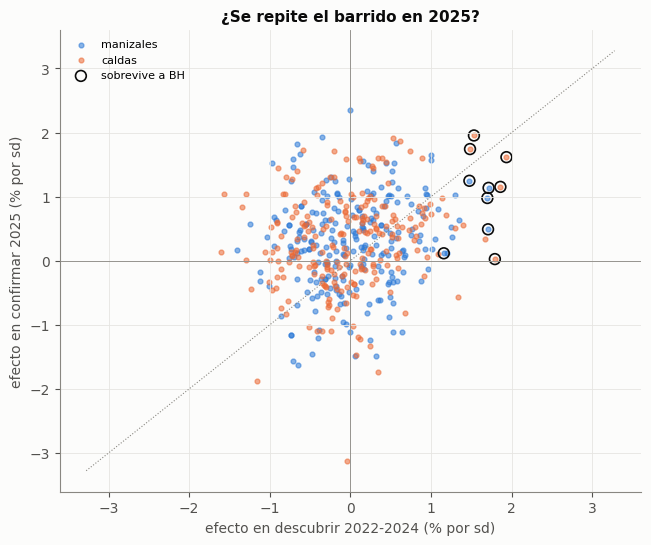

Con el desenlace sin su estación (sección 4b): r(descubrir, confirmar) = 0.05 | mismo signo: 52 %


pruebas           r desc-conf           mismo signo %           r desc-conf, y sin estación           mismo signo %, y sin estación          
ámbito              caldas manizales      caldas manizales        caldas manizales                      caldas manizales                        caldas manizales
familia                                                                                                                                                         
contagio              16.0      16.0       -0.14      0.08          50.0      56.0                       -0.45     -0.21                          25.0      50.0
crónico               32.0      32.0        0.21      0.12          66.0      44.0                       -0.39     -0.18                          34.0      41.0
gastro                56.0      56.0        0.50      0.35          82.0      84.0                        0.08     -0.09                          32.0      30.0
intoxicaciones        16.0      16.0        0.58      0.44          75.0      56.0                        0.62      0.36                          62.0      75.0
lesiones               8.0       8.0        0.38      0.17          38.0      62.0                        0.66      0.26                          62.0      38.0
materno                8.0       8.0        0.14     -0.44          75.0      25.0                        0.35     -0.21                          75.0      25.0
nutrición              8.0       8.0        0.27      0.37          88.0      88.0                       -0.10      0.44                          38.0      50.0
respiratorio          48.0      56.0        0.22      0.36          42.0      46.0                       -0.21     -0.32                          73.0      86.0
respiratorio grave    24.0      24.0        0.18      0.11          33.0      54.0                        0.06      0.03                          67.0      67.0
salud mental           8.0       8.0        0.18      0.44          38.0      75.0                        0.11      0.25                          38.0      62.0
violencia              8.0       8.0        0.26     -0.79          12.0      12.0                        0.24     -0.77                          50.0      38.0

In [9]:
filas = []
for (amb, nom), a in A.items():
    if amb == "colombia": continue
    a = a.reindex(yv.index)
    for k in REZ[1:]:
        sd = B[(B.ámbito == amb) & (B.serie == nom) & (B.rezago == k)].sd_desc.iloc[0]
        b, se, p, n, _ = ajuste(yv, a, k, CONF, sd=sd)
        filas.append({"ámbito": amb, "serie": nom, "rezago": k, "efecto % 2025": 100 * b, "p 2025": p})
        # Lo mismo con el desenlace sin su estación (sección 4b), en los dos periodos
        bd, *_r, sdd = ajuste(yv_des, a, k, DESC)
        bc, *_r = ajuste(yv_des, a, k, CONF, sd=sdd)
        filas[-1].update({"efecto % desc (y sin estación)": 100 * bd, "efecto % 2025 (y sin estación)": 100 * bc})
C = B[B.rezago.ge(1)].merge(pd.DataFrame(filas), on=["ámbito", "serie", "rezago"])
r_todo = C["efecto %"].corr(C["efecto % 2025"])
acuerdo = (np.sign(C["efecto %"]) == np.sign(C["efecto % 2025"])).mean()
fuertes = C[C.p < .05]
print(f"{len(C)} pruebas con rezago >= 1 | r(descubrir, confirmar) = {r_todo:.2f} | mismo signo: {100 * acuerdo:.0f} %")
print(f"Entre las {len(fuertes)} con p < 0,05 en descubrir: mismo signo en 2025 el {100 * (np.sign(fuertes['efecto %']) == np.sign(fuertes['efecto % 2025'])).mean():.0f} %")
fig, ax = plt.subplots(figsize=(7.5, 6))
for amb, col in [("manizales", AZUL), ("caldas", NARANJA)]:
    c = C[C.ámbito.eq(amb)]
    ax.scatter(c["efecto %"], c["efecto % 2025"], s=12, alpha=.55, color=col, label=amb)
s = C[C["sobrevive BH"]]
ax.scatter(s["efecto %"], s["efecto % 2025"], s=60, facecolors="none", edgecolors=TINTA, lw=1.2, label="sobrevive a BH")
lim = np.nanmax(np.abs(C[["efecto %", "efecto % 2025"]].values)) * 1.05
ax.plot([-lim, lim], [-lim, lim], color=MUDO, lw=.8, ls=":"); ax.axhline(0, color=MUDO, lw=.6); ax.axvline(0, color=MUDO, lw=.6)
ax.set_xlabel("efecto en descubrir 2022-2024 (% por sd)"); ax.set_ylabel("efecto en confirmar 2025 (% por sd)")
ax.set_title("¿Se repite el barrido en 2025?"); ax.legend(fontsize=8); plt.show()
ye, ce = "efecto % desc (y sin estación)", "efecto % 2025 (y sin estación)"
print(f"Con el desenlace sin su estación (sección 4b): r(descubrir, confirmar) = {C[ye].corr(C[ce]):.2f} | "
      f"mismo signo: {100 * (np.sign(C[ye]) == np.sign(C[ce])).mean():.0f} %")
C.groupby(["ámbito", "familia"]).apply(lambda g: pd.Series({"pruebas": len(g), "r desc-conf": round(g["efecto %"].corr(g["efecto % 2025"]), 2),
                                                               "mismo signo %": round(100 * (np.sign(g["efecto %"]) == np.sign(g["efecto % 2025"])).mean()),
                                                               "r desc-conf, y sin estación": round(g[ye].corr(g[ce]), 2),
                                                               "mismo signo %, y sin estación": round(100 * (np.sign(g[ye]) == np.sign(g[ce])).mean())})).unstack(0)

## Lectura de la confirmación

**El barrido entero se repite poco: r = 0,18 entre los efectos de 2022-2024 y los de 2025, y el 58 % mantiene el signo** (el azar daría cerca de 0 y 50 %). Entre las 46 pruebas con p < 0,05 en descubrir, el 74 % mantiene el signo.

Por familia, lo único que se repite con claridad es lo **gastro**: r = 0,50 en Caldas y 0,35 en Manizales, con el 82-84 % del signo igual. Lo respiratorio no se repite (42-46 % del signo). La violencia en Manizales **se invierte** (r = −0,79): lo que en 2022-2024 iba en una dirección, en 2025 va en la contraria.

**Con el desenlace sin su estación la repetición desaparece: r = 0,05 y el 52 % del signo.** La familia gastro cae a 0,08 y −0,09, con el 30-32 % del signo igual. Lo que se repetía era la época del año y no la anomalía; la sección 4b lo desarrolla.

Lo único que conserva algo sin estación son las **intoxicaciones** (r = 0,62 y 0,36), ninguna de cuyas pruebas pasó BH y que además son series con fuga posible. Se anota sin más peso.

**Límite.** Las pruebas de una misma serie en rezagos vecinos no son independientes: los 472 puntos equivalen a muchos menos. Los porcentajes de signo son una lectura de conjunto y no una prueba.

---
# 4. Un índice general: la «presión epidemiológica» de la ciudad

El índice se construye con componentes principales de las anomalías de Manizales, **ajustados solo en descubrir** y proyectados en 2025. Al modelo entrarían índices y no decenas de series.

Qué series entran y cuáles no:
- Se usan las **bandas de edad** de IRA y de EDA y no los totales, que serían su suma y pesarían doble.
- Quedan fuera la IRA sin SES (casi idéntica a la IRA total, sección 1), el cáncer (sin 2022), la tuberculosis pulmonar (es parte del 813) y la intoxicación por fármacos (es parte del 365).
- Cada serie se estandariza con la media y la desviación de descubrir.

157 semanas de ajuste, 24 series
Varianza explicada (%): {'PC1': 18.4, 'PC2': 11.2, 'PC3': 8.2, 'PC4': 6.5, 'PC5': 5.9, 'PC6': 5.2}
Parecido de las cargas con una PCA ajustada solo en 2025 (|r| con el componente más parecido): {'PC1': 0.66, 'PC2': 0.73, 'PC3': 0.54, 'PC4': 0.43}
Varianza que conserva cada componente proyectado en 2025 (%): {'PC1': 11.7, 'PC2': 9.4, 'PC3': 6.0, 'PC4': 4.0}


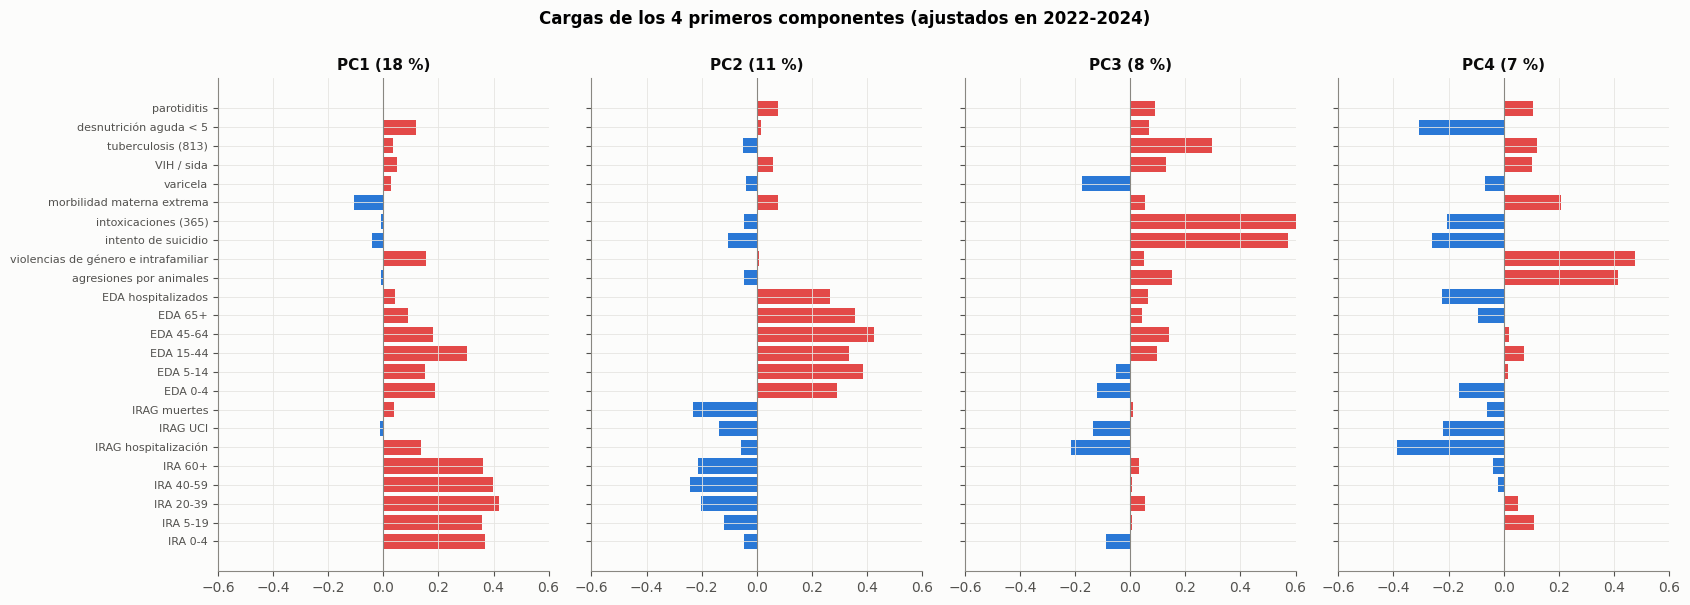

,PC1,PC2,PC3,PC4
IRA 0-4,0.37,-0.05,-0.09,0.00
IRA 5-19,0.36,-0.12,0.01,0.11
IRA 20-39,0.42,-0.20,0.05,0.05
IRA 40-59,0.40,-0.24,0.01,-0.02
IRA 60+,0.36,-0.21,0.03,-0.04
IRAG hospitalización,0.14,-0.06,-0.21,-0.39
IRAG UCI,-0.01,-0.14,-0.13,-0.22
IRAG muertes,0.04,-0.23,0.01,-0.06
EDA 0-4,0.19,0.29,-0.12,-0.16
EDA 5-14,0.15,0.39,-0.05,0.02


In [10]:
EN_PCA = [f"IRA {b.replace('_', '-').replace('-mas', '+')}" for b in BANDAS_IRA] + ["IRAG hospitalización", "IRAG UCI", "IRAG muertes"] + \
         [f"EDA {b.replace('_', '-').replace('-mas', '+')}" for b in BANDAS_EDA] + ["EDA hospitalizados"] + \
         [NOMBRE_EV[e] for e in (300, 875, 356, 365, 549, 831, 850, 813, 113, 620)]
X = pd.DataFrame({n: A[("manizales", n)] for n in EN_PCA})
Xd = X.loc["2022-01-02":DESC[1]].dropna()
mu, sd = Xd.mean(), Xd.std()
pca = PCA(n_components=6).fit(((Xd - mu) / sd).values)
carg = pd.DataFrame(pca.components_.T, index=EN_PCA, columns=[f"PC{i+1}" for i in range(6)])
signo = np.sign(carg.apply(lambda c: c[c.abs().idxmax()]))           # la carga mayor, positiva
carg = carg * signo
Z = pd.DataFrame(((X.dropna() - mu) / sd).values @ carg.values, index=X.dropna().index, columns=carg.columns)
print(f"{len(Xd)} semanas de ajuste, {len(EN_PCA)} series")
print("Varianza explicada (%):", dict(zip(carg.columns, (100 * pca.explained_variance_ratio_).round(1))))
# Estabilidad: la misma PCA ajustada en 2025, ¿da las mismas cargas?
Xc = X.loc[CONF[0]:CONF[1]].dropna()
pca_c = PCA(n_components=4).fit(((Xc - Xc.mean()) / Xc.std()).values)
estab = {f"PC{i+1}": round(max(abs(np.corrcoef(carg[f'PC{i+1}'], pca_c.components_[j])[0, 1]) for j in range(4)), 2) for i in range(4)}
print("Parecido de las cargas con una PCA ajustada solo en 2025 (|r| con el componente más parecido):", estab)
var_conf = {c: round(100 * Z.loc[CONF[0]:CONF[1], c].var() / (((Xc - mu) / sd).var().sum()), 1) for c in carg.columns[:4]}
print("Varianza que conserva cada componente proyectado en 2025 (%):", var_conf)
fig, axes = plt.subplots(1, 4, figsize=(17, 6), sharey=True)
for ax, c in zip(axes, carg.columns[:4]):
    v = carg[c]
    ax.barh(range(len(v)), v.values, color=[ROJO if x > 0 else AZUL for x in v.values])
    ax.axvline(0, color=MUDO, lw=.8); ax.set_title(f"{c} ({100 * pca.explained_variance_ratio_[int(c[2:]) - 1]:.0f} %)")
    ax.set_yticks(range(len(v)), v.index, fontsize=8); ax.invert_yaxis(); ax.set_xlim(-.6, .6)
plt.suptitle("Cargas de los 4 primeros componentes (ajustados en 2022-2024)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()
carg.iloc[:, :4].round(2)

## Lectura del índice

**La salud de la ciudad no tiene un eje dominante.** Con 24 series y 157 semanas de ajuste (2022-01 a 2024-12), los 4 primeros componentes explican el **44 %** de la varianza (18,4 + 11,2 + 8,2 + 6,5):

| Componente | Varianza | Cargas altas | Nombre | Estabilidad en 2025 |
|---|---|---|---|---|
| **PC1** | 18,4 % | Las 5 bandas de IRA (0,36 a 0,42), EDA 15-44 (0,30) | **Respiratorio de la ciudad** | Parecido 0,66; conserva 11,7 % |
| **PC2** | 11,2 % | Las 5 bandas de EDA (0,29 a 0,43), EDA hospitalizada (0,26), frente a IRA e IRAG (−0,20 a −0,24) | **Gastro, en contra de lo respiratorio** | Parecido 0,73; conserva 9,4 % |
| **PC3** | 8,2 % | Intoxicaciones (0,60), intento de suicidio (0,57), tuberculosis (0,30) | **Salud mental e intoxicaciones** | Parecido 0,54; conserva 6,0 % |
| **PC4** | 6,5 % | Violencias (0,48), agresiones por animales (0,41), frente a IRAG hospitalizada (−0,39) y desnutrición (−0,31) | **Violencia y lesiones** | Parecido 0,43; conserva 4,0 % |

- **PC1 y PC2 son reconocibles y bastante estables.** Son las dos grandes familias de circulación comunitaria, la respiratoria y la gastrointestinal. PC2 las opone: las semanas con más EDA de lo normal tienden a tener menos IRA.
- **PC3 y PC4 son frágiles.** Una PCA ajustada solo con 2025 las reproduce a medias (0,54 y 0,43). Reúnen eventos de pocas decenas de casos por semana, donde el ruido de conteo pesa mucho.
- Lo grave (IRAG en UCI y muertes) no tiene componente propio: carga poco en todos.

**Límite.** «Parecido» es la correlación de las cargas con el componente más parecido de una PCA de 2025, que solo tiene 52 semanas. Es orientativo.

## Los componentes frente al triage y frente a sus desenlaces específicos

Cada componente, con rezagos de 0 a 8, se contrasta con `y` y con los desenlaces secundarios (`y_respiratorio`, `y_infecciosas`, `y_trauma`) en descubrir. BH con q = 0,10 sobre esta familia (4 componentes × 4 desenlaces × 9 rezagos). El rezago 0 entra en la familia pero no cuenta. Lo que sobrevive se confirma en 2025 con el criterio de antes.

Pruebas: 144 | sobreviven a BH: 10 (rezago >= 1: 8) | confirmadas en 2025: 1
Contra y (triage total), efecto máximo en valor absoluto, % por sd: {'PC1': 1.71, 'PC2': 1.2, 'PC3': 1.19, 'PC4': 1.05}


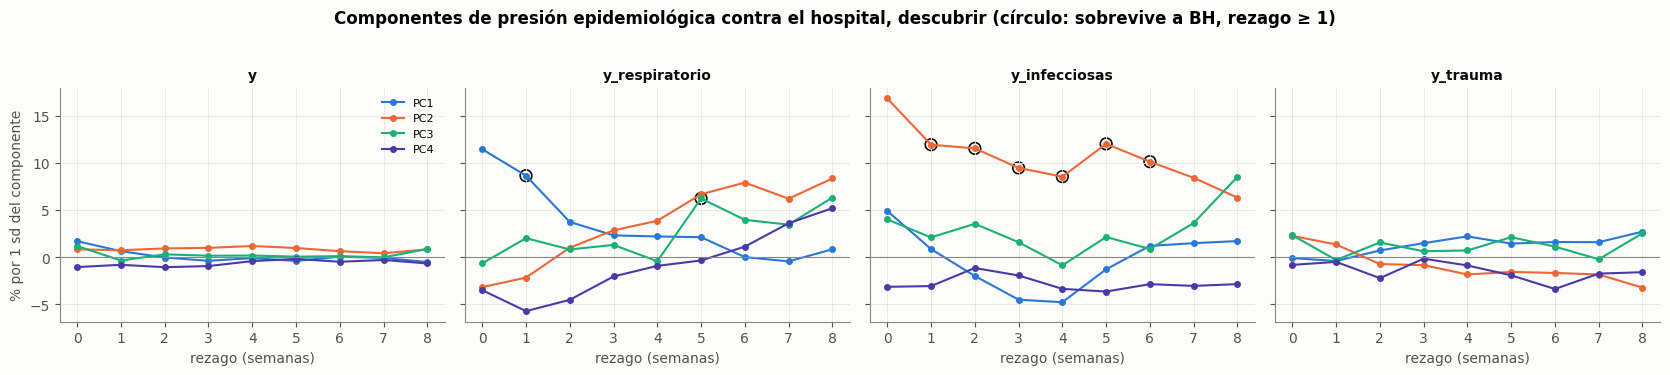

,desenlace,componente,rezago,efecto %,p,efecto % 2025,p unilateral 2025,q,sobrevive BH,confirmada
0,y_infecciosas,PC2,0,16.848,0.001,2.278,0.375,0.023,True,False
1,y_infecciosas,PC2,1,11.942,0.006,4.766,0.198,0.080,True,False
2,y_infecciosas,PC2,2,11.554,0.000,-0.427,0.530,0.023,True,False
3,y_infecciosas,PC2,3,9.481,0.001,-3.548,0.707,0.025,True,False
4,y_infecciosas,PC2,4,8.556,0.005,-4.351,0.723,0.080,True,False
5,y_infecciosas,PC2,5,12.031,0.001,2.253,0.344,0.023,True,False
6,y_infecciosas,PC2,6,10.142,0.004,2.205,0.344,0.080,True,False
7,y_respiratorio,PC1,0,11.466,0.000,14.439,0.012,0.001,True,False
8,y_respiratorio,PC1,1,8.656,0.002,10.609,0.055,0.053,True,False
9,y_respiratorio,PC3,5,6.240,0.003,9.141,0.005,0.071,True,True


In [11]:
DESENLACES = [c for c in ["y", "y_respiratorio", "y_infecciosas", "y_trauma"] if c in Y.columns]
filas = []
for des in DESENLACES:
    yy = Y[des].reindex(yv.index)
    for c in carg.columns[:4]:
        z = Z[c].reindex(yv.index)
        for k in REZ:
            b, se, p, n, sdz = ajuste(yy, z, k, DESC)
            b2, se2, p2, n2, _ = ajuste(yy, z, k, CONF, sd=sdz)
            filas.append({"desenlace": des, "componente": c, "rezago": k, "efecto %": 100 * b, "p": p,
                          "efecto % 2025": 100 * b2, "p unilateral 2025": p2 / 2 if np.sign(b2) == np.sign(b) else 1 - p2 / 2})
P = pd.DataFrame(filas)
P["q"] = multipletests(P.p, method="fdr_bh")[1]
P["sobrevive BH"] = P.q < q_BH
P["confirmada"] = P["sobrevive BH"] & P.rezago.ge(1) & (P["p unilateral 2025"] < .05)
print(f"Pruebas: {len(P)} | sobreviven a BH: {P['sobrevive BH'].sum()} (rezago >= 1: {(P['sobrevive BH'] & P.rezago.ge(1)).sum()}) "
      f"| confirmadas en 2025: {P.confirmada.sum()}")
print("Contra y (triage total), efecto máximo en valor absoluto, % por sd:",
      P[P.desenlace.eq("y")].groupby("componente")["efecto %"].apply(lambda s: round(s.abs().max(), 2)).to_dict())
fig, axes = plt.subplots(1, len(DESENLACES), figsize=(4.2 * len(DESENLACES), 3.6), sharey=True)
for ax, des in zip(np.atleast_1d(axes), DESENLACES):
    for c, col in zip(carg.columns[:4], [AZUL, NARANJA, AQUA, VIOLETA]):
        p_ = P[(P.desenlace == des) & (P.componente == c)]
        ax.plot(p_.rezago, p_["efecto %"], marker="o", ms=4, color=col, label=c)
        s_ = p_[p_["sobrevive BH"] & p_.rezago.ge(1)]
        ax.scatter(s_.rezago, s_["efecto %"], s=70, facecolors="none", edgecolors=TINTA, lw=1.2)
    ax.axhline(0, color=MUDO, lw=.8); ax.set_title(des, fontsize=10); ax.set_xlabel("rezago (semanas)")
np.atleast_1d(axes)[0].set_ylabel("% por 1 sd del componente"); np.atleast_1d(axes)[0].legend(fontsize=8)
plt.suptitle("Componentes de presión epidemiológica contra el hospital, descubrir (círculo: sobrevive a BH, rezago ≥ 1)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()
P[P["sobrevive BH"] | P.confirmada].round(3).sort_values(["desenlace", "componente", "rezago"]).reset_index(drop=True)

## Lectura de los componentes

**Frente al triage total, ningún componente pasa de ±1,7 % por desviación típica** (PC1 1,71; PC2 1,20; PC3 1,19; PC4 1,05) y nada sobrevive a BH. La presión epidemiológica de la ciudad **no mueve el total del hospital de forma visible**.

**Frente a los desenlaces específicos sí se ve, y con tamaño.** De 144 pruebas sobreviven 10 (8 con rezago de 1 o más):

| Componente → desenlace | Rezago | Descubrir | 2025 | Lectura |
|---|---|---|---|---|
| **PC1 (respiratorio) → respiratorio del hospital** | 0 | **+11,5 %** | **+14,4 %** (p 0,012) | La ola de la ciudad y la del hospital van juntas. **No cuenta**: rezago 0 |
| **PC1 → respiratorio** | **1** | **+8,7 %** (q 0,053) | **+10,6 %** (p 0,055) | Mismo signo y tamaño; **queda justo fuera** del criterio (0,055 frente a 0,05) |
| PC2 (gastro) → infecciosas | 1 a 6 | +8,6 a +12,0 % | −4,4 a +4,8 % | No se repite |
| PC3 (salud mental) → respiratorio | 5 | +6,2 % | +9,1 % (p 0,005) | Confirmado, **sin mecanismo**: sección 4b |

- **Aquí aparece, medido, el argumento de la dilución.** Una desviación típica de ola respiratoria en la ciudad acompaña a +11 a +14 % de consultas respiratorias en el hospital esa misma semana, y a menos de +2 % del total. El efecto existe, pero **se diluye en el total**.
- **PC1 a una semana** es el único resultado con mecanismo claro (contagio comunitario, luego consulta), con el mismo tamaño y signo en los dos periodos. No pasa el criterio fijado (p 0,055 frente a 0,05); no se da por confirmado y se mantiene como el candidato mejor situado. Las secciones 7 a 9 lo vuelven a medir con otro diseño.
- **La gastro de la ciudad no anticipa las infecciosas del hospital en 2025**, pese a +9 a +12 % en descubrir.

**Límite.** Los desenlaces específicos salen de los diagnósticos agregados del cuaderno 10. Son más ruidosos que el total y su codificación puede haber cambiado entre años.

---
# 4b. Lo confirmado acompaña a la estación y no la anticipa

Esta prueba se añadió después de ver que lo confirmado se repite en rezagos contiguos (3, 4, 5 y 6 semanas), que es la firma de dos series que se mueven juntas y despacio, no la de un gatillo con su reloj. No formaba parte del diseño inicial y se declara como añadida. Se hacen dos preguntas a cada resultado confirmado:

1. **Rezagos negativos.** Si el **triage** «predice» la serie de vigilancia tan bien como la serie predice al triage, ambas se mueven juntas y ninguna va antes.
2. **Desenlace sin su estación.** El desenlace conserva la estacionalidad a propósito (`desenlace.py`). Pero la anomalía de vigilancia solo quita la forma estacional **típica de 2015-2024**; si la forma de los años recientes es otra, a la anomalía le queda algo de estación y puede coincidir con la del hospital. Se repite la prueba con el desenlace sin su propia forma estacional (3 armónicos ajustados en descubrir). Si el efecto desaparece, lo que explicaba era **la época del año**, que ya se conoce por el calendario: eso es proyección y no predicción.

4 resultados confirmados que revisar


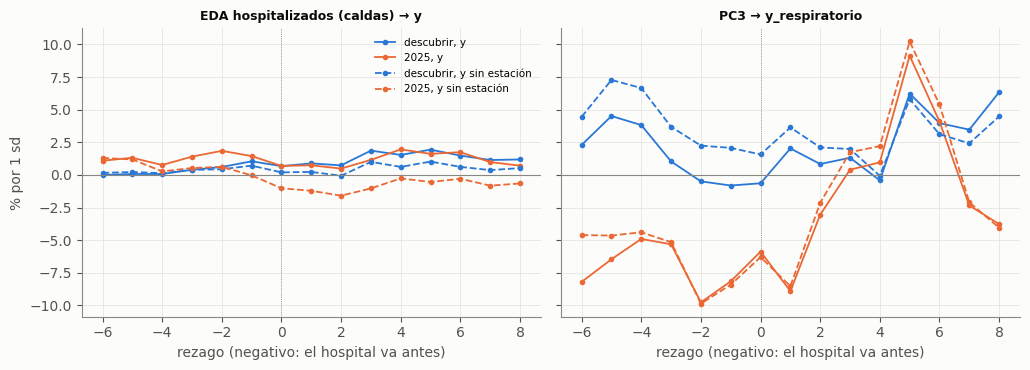

resultado confirmado,EDA hospitalizados (caldas) → y,EDA hospitalizados (caldas) → y,EDA hospitalizados (caldas) → y,PC3 → y_respiratorio
rezago,4.000,5.000,6.000,5.000
"y, desc: efecto %",1.530,1.940,1.480,6.240
"y, desc: p",0.001,0.000,0.002,0.003
"y, 2025: efecto %",1.960,1.620,1.740,9.140
"y, 2025: p",0.028,0.055,0.005,0.010
"y sin estación, desc: efecto %",0.610,1.020,0.620,5.810
"y sin estación, desc: p",0.064,0.014,0.097,0.005
"y sin estación, 2025: efecto %",-0.270,-0.540,-0.300,10.230
"y sin estación, 2025: p",0.734,0.485,0.682,0.002
triage antes (2025): mejor rezago,-2.000,-2.000,-2.000,-6.000


In [12]:
confirmados = []
if len(SOB):
    for _, r in SOB[SOB.confirmada].iterrows():
        confirmados.append((f"{r.serie} ({r.ámbito}) → y", A[(r.ámbito, r.serie)], "y", r.rezago))
for _, r in P[P.confirmada].iterrows():
    confirmados.append((f"{r.componente} → {r.desenlace}", Z[r.componente], r.desenlace, r.rezago))
filas, curvas = [], {}
for etiqueta, x, des, k in confirmados:
    yy = Y[des].reindex(yv.index); yd = sin_estacion(yy); x = x.reindex(yv.index)
    fila = {"resultado confirmado": etiqueta, "rezago": k}
    for nom_y, serie_y in [("y", yy), ("y sin estación", yd)]:
        for per_nom, per in [("desc", DESC), ("2025", CONF)]:
            sdx = ajuste(serie_y, x, k, DESC)[4]
            b, se, p2, n, _ = ajuste(serie_y, x, k, per, sd=sdx)
            fila[f"{nom_y}, {per_nom}: efecto %"] = round(100 * b, 2)
            fila[f"{nom_y}, {per_nom}: p"] = round(p2, 3)
    neg = [(j, *ajuste(yy, x, -j, CONF, sd=ajuste(yy, x, -j, DESC)[4])[:3]) for j in range(1, 7)]
    j, b, se, p = min(neg, key=lambda t: t[3])
    fila["triage antes (2025): mejor rezago"] = -j; fila["triage antes (2025): efecto %"] = round(100 * b, 2); fila["triage antes (2025): p"] = round(p, 3)
    filas.append(fila)
    curvas[etiqueta] = pd.DataFrame({per_nom: {kk: 100 * ajuste(sy, x, kk, per, sd=ajuste(sy, x, kk, DESC)[4])[0] for kk in range(-6, 9)}
                                     for per_nom, per, sy in [("descubrir, y", DESC, yy), ("2025, y", CONF, yy),
                                                              ("descubrir, y sin estación", DESC, yd), ("2025, y sin estación", CONF, yd)]})
print(f"{len(confirmados)} resultados confirmados que revisar")
if curvas:
    fig, axes = plt.subplots(1, len(curvas), figsize=(5.2 * len(curvas), 3.8), sharey=True)
    for ax, (et, cu) in zip(np.atleast_1d(axes), curvas.items()):
        for c, col, ls in [("descubrir, y", AZUL, "-"), ("2025, y", NARANJA, "-"), ("descubrir, y sin estación", AZUL, "--"), ("2025, y sin estación", NARANJA, "--")]:
            ax.plot(cu.index, cu[c], color=col, ls=ls, marker="o", ms=3, lw=1.3, label=c)
        ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.6, ls=":")
        ax.set_title(et, fontsize=9); ax.set_xlabel("rezago (negativo: el hospital va antes)")
    np.atleast_1d(axes)[0].set_ylabel("% por 1 sd"); np.atleast_1d(axes)[0].legend(fontsize=7.5)
    plt.tight_layout(); plt.show()
pd.DataFrame(filas).set_index("resultado confirmado").T

In [13]:
# Cuántas confirmaciones daría el azar, y de qué está hecho cada componente confirmado
n_prob_barr, n_prob_pca = len(SOB), int((P["sobrevive BH"] & P.rezago.ge(1)).sum())
print(f"Confirmaciones esperadas por azar (p unilateral < 0,05): barrido {0.05 * n_prob_barr:.1f} de {n_prob_barr}; "
      f"componentes {0.05 * n_prob_pca:.1f} de {n_prob_pca}")
filas = []
for _, r in P[P.confirmada].iterrows():
    yy = Y[r.desenlace].reindex(yv.index)
    for n in carg[r.componente].abs().sort_values(ascending=False).index[:6]:
        x = A[("manizales", n)].reindex(yv.index)
        b, _, p, _, sdx = ajuste(yy, x, r.rezago, DESC); b2, _, p2, _, _ = ajuste(yy, x, r.rezago, CONF, sd=sdx)
        filas.append({"componente → desenlace": f"{r.componente} → {r.desenlace}, rezago {r.rezago}", "serie": n,
                      "carga": round(carg.loc[n, r.componente], 2), "efecto % desc": round(100 * b, 1), "p desc": round(p, 3),
                      "efecto % 2025": round(100 * b2, 1), "p 2025": round(p2, 3)})
pd.DataFrame(filas).set_index(["componente → desenlace", "serie"]) if filas else "ningún componente confirmado"

Confirmaciones esperadas por azar (p unilateral < 0,05): barrido 0.5 de 10; componentes 0.4 de 8


carga  efecto % desc  p desc  efecto % 2025  p 2025
componente → desenlace         serie                                                                       
PC3 → y_respiratorio, rezago 5 intoxicaciones (365)      0.60            3.9   0.071            8.9   0.007
                               intento de suicidio       0.57            2.9   0.251            6.0   0.061
                               tuberculosis (813)        0.30            0.2   0.947           -3.0   0.427
                               IRAG hospitalización     -0.21           -2.9   0.361          -13.4   0.002
                               varicela                 -0.17           -3.7   0.270            9.6   0.001
                               agresiones por animales   0.15            0.7   0.774           -6.9   0.037

## Lectura de la prueba de estación

**Ninguno de los 4 resultados confirmados resiste, y lo confirmado no es anticipación.**

**1. EDA hospitalizados de Caldas → triage (rezagos 4, 5 y 6): acompaña a la estación y no la anticipa.**
- Con el desenlace sin estación, el efecto en 2025 pasa de +1,6 a +2,0 % a **−0,3 a −0,5 %** (p de 0,48 a 0,73). En descubrir también se reduce a la mitad o menos (+0,6 a +1,0 %).
- En 2025, el **triage** «predice» la EDA hospitalizada dos semanas después casi igual (+1,84 %, p 0,031). Las dos series se mueven juntas y despacio; ninguna va antes.
- Por qué queda estación en la anomalía [I]: la EDA hospitalizada **casi se duplicó** entre 2019 y 2024 (sección 1) mientras la EDA total caía. La forma estacional típica se ajustó con años en que la serie era otra cosa, y a la anomalía le queda la época del año de los años recientes, que coincide con la del hospital.
- **Consecuencia:** explica la época del año, que ya aporta el calendario. Es proyección y no predicción.

**2. PC3 (salud mental e intoxicaciones) → respiratorio del hospital (rezago 5): azar con apariencia de hallazgo.**
- Resiste la prueba de estación (+10,2 % en 2025, p 0,002), pero:
  - **ninguna de sus series lo lleva en descubrir:** intoxicaciones +3,9 % (p 0,071), intento de suicidio +2,9 % (p 0,25), tuberculosis +0,2 %;
  - **en 2025 lo llevan otras series, con signos que no cuadran:** la hospitalización por IRAG va a −13,4 % y la varicela a +9,6 %;
  - la curva de 2025 cambia de signo entre rezagos vecinos (figura), de modo que no tiene la forma de un reloj;
  - no hay mecanismo por el que los intentos de suicidio anticipen consultas respiratorias cinco semanas después;
  - de las 8 pruebas de componentes que se llevaron a 2025, **el azar daría 0,4 confirmaciones**; que haya una es lo esperable.

**Por qué esta sección importa para el sobreajuste.** Con el criterio fijado de antemano, el cuaderno habría dado por buenos dos «predictores». Los dos caen con una pregunta más: **si la serie va antes o solo va a la vez**. Desde aquí, ningún resultado confirmado se acepta sin la prueba de estación y la de rezagos negativos.

**Límite que reaparece en la sección 7.** La prueba de estación es conservadora: si una ola ocurre siempre en la misma época, quitar la estación del desenlace quita también parte del efecto real. En ese caso el resultado correcto es «no se puede separar de la fecha» y no «no afecta».

---
# 5. La ciudad, el departamento y el país: quién va antes

Se compara la IRA y la EDA de Manizales con **Caldas sin Manizales** (Caldas incluye a Manizales, y compararla consigo misma daría una correlación mecánica) y con **Colombia**. Dos miradas, en anomalía, 2022-2025:
1. **Correlación cruzada** con rezagos de −8 a +8 semanas. Un pico en rezago positivo indica que la otra geografía va **antes** que Manizales.
2. **Prueba de precedencia (tipo Granger), con errores HAC:** si las 2 semanas previas de Caldas o de Colombia mejoran la predicción de Manizales cuando ya se conocen sus propias 2 semanas previas, y a la inversa.

Una salvedad: las tres geografías comparten el calendario nacional (Semana Santa, festivos), que mueve la consulta la misma semana en todas partes. Por eso un rezago 0 alto no dice quién va antes.

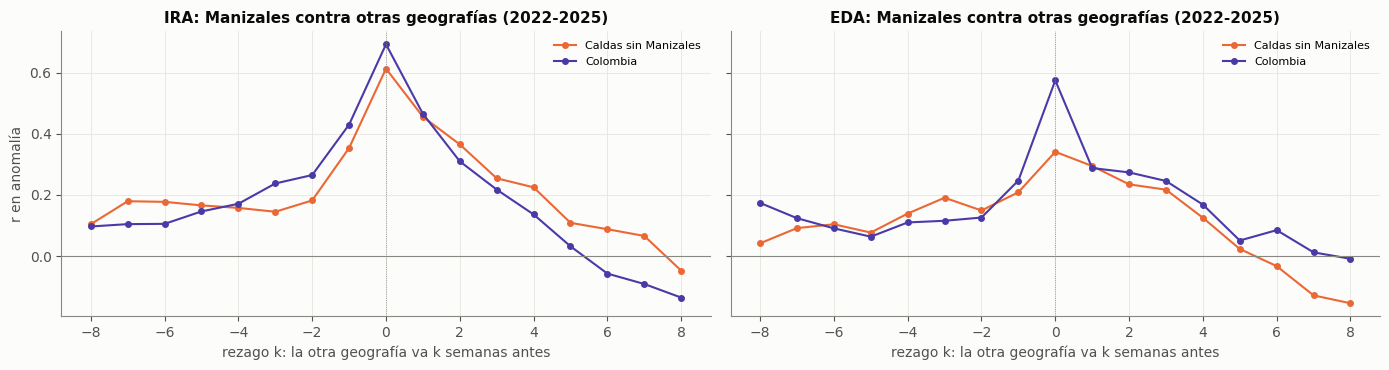

,serie,sentido,r rezago 0,r mejor rezago,mejor rezago,coef. semana previa,p precedencia (HAC),semanas
0,IRA,Caldas sin Manizales → Manizales,0.61,0.61,0,0.150,0.0089,207
1,IRA,Manizales → Caldas sin Manizales,0.61,0.61,0,0.068,0.5512,207
2,IRA,Colombia → Manizales,0.69,0.69,0,0.282,0.2453,207
3,IRA,Manizales → Colombia,0.69,0.69,0,-0.045,0.5860,207
4,EDA,Caldas sin Manizales → Manizales,0.34,0.34,0,0.163,0.1032,206
5,EDA,Manizales → Caldas sin Manizales,0.34,0.34,0,0.044,0.6997,206
6,EDA,Colombia → Manizales,0.58,0.58,0,-0.031,0.5522,206
7,EDA,Manizales → Colombia,0.58,0.58,0,0.004,0.5721,207


In [14]:
def resta(a, b): return (a - b).where((a - b) > 0)
pares = {}
for nom, ev, var in [("IRA", 995, "consultas_ira_total"), ("EDA", 998, "casos_eda_total")]:
    man = serie("manizales", ev, var); cal = serie("caldas", ev, var); col = serie("colombia", ev, var)
    pares[nom] = {"Manizales": anomalia(man), "Caldas sin Manizales": anomalia(resta(cal, man)), "Colombia": anomalia(col)}
K = range(-8, 9)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True); filas = []
for ax, (nom, d) in zip(axes, pares.items()):
    m = d["Manizales"].loc["2022":"2025"]
    for otro, col in [("Caldas sin Manizales", NARANJA), ("Colombia", VIOLETA)]:
        o = d[otro]
        rs = [m.corr(o.shift(k).reindex(m.index)) for k in K]
        ax.plot(list(K), rs, marker="o", ms=4, color=col, label=otro)
        # precedencia
        D = pd.DataFrame({"m": m, "o": o.reindex(m.index)})
        for sentido, (dep, ind) in {f"{otro} → Manizales": ("m", "o"), f"Manizales → {otro}": ("o", "m")}.items():
            Xg = pd.DataFrame({"c": 1.0, "p1": D[dep].shift(1), "p2": D[dep].shift(2), "x1": D[ind].shift(1), "x2": D[ind].shift(2)})
            dd = pd.concat([D[dep].rename("dep"), Xg], axis=1).dropna()
            g = sm.OLS(dd.dep, dd.drop(columns="dep")).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
            w = g.wald_test("x1 = 0, x2 = 0", scalar=True)
            filas.append({"serie": nom, "sentido": sentido, "r rezago 0": round(rs[8], 2),
                          "r mejor rezago": round(max(rs, key=abs), 2), "mejor rezago": list(K)[int(np.argmax(np.abs(rs)))],
                          "coef. semana previa": round(g.params["x1"], 3), "p precedencia (HAC)": round(float(w.pvalue), 4), "semanas": len(dd)})
    ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.6, ls=":")
    ax.set_title(f"{nom}: Manizales contra otras geografías (2022-2025)"); ax.set_xlabel("rezago k: la otra geografía va k semanas antes")
    ax.legend(fontsize=8)
axes[0].set_ylabel("r en anomalía"); plt.tight_layout(); plt.show()
pd.DataFrame(filas)

## Lectura de las geografías

**La ciudad, el resto del departamento y el país enferman a la vez. En la IRA, el resto de Caldas va un poco antes que Manizales; al revés, no.**

| | r a la vez | Mejor rezago | Otra → Manizales (p) | Manizales → otra (p) |
|---|---|---|---|---|
| IRA, Caldas sin Manizales | 0,61 | 0 | **0,009** (coef. 0,15) | 0,55 |
| IRA, Colombia | 0,69 | 0 | 0,25 | 0,59 |
| EDA, Caldas sin Manizales | 0,34 | 0 | 0,10 | 0,70 |
| EDA, Colombia | 0,58 | 0 | 0,55 | 0,57 |

- **La correlación más alta es siempre a la vez** (rezago 0): es el calendario nacional compartido y la circulación simultánea.
- **La IRA del resto de Caldas añade información sobre la de Manizales de una semana después**, aun conociendo las dos semanas previas de Manizales (p = 0,009). En sentido contrario no hay nada (p = 0,55). La precedencia es **pequeña**: 0,15 de cada unidad de anomalía pasa a Manizales una semana más tarde. Encaja con un contagio que llega a la capital desde los municipios, o con una notificación más rápida fuera de Manizales; con estos datos no se separan.
- **Colombia no anticipa a Manizales** en la IRA (p = 0,25) ni en la EDA: va a la vez.
- La EDA del departamento se parece poco a la de la ciudad (0,34): la diarrea es más local, por brotes.

**Límite.** Son 206 o 207 semanas de 2022-2025 y una sola prueba por par, sin corrección por multiplicidad (8 pruebas: con Bonferroni, 0,009 × 8 = 0,07).

## El departamento frente al hospital

Lo que importa al final no es si Caldas anticipa a Manizales, sino si **anticipa al triage** mejor que la propia ciudad. Se repite el barrido de la sección 2 con la IRA y la EDA de Caldas sin Manizales y de Colombia, rezagos de 1 a 8 semanas, en descubrir y en 2025. Es exploratorio: no formaba parte de la familia fijada de antemano, y se lee solo junto a la IRA de Manizales.

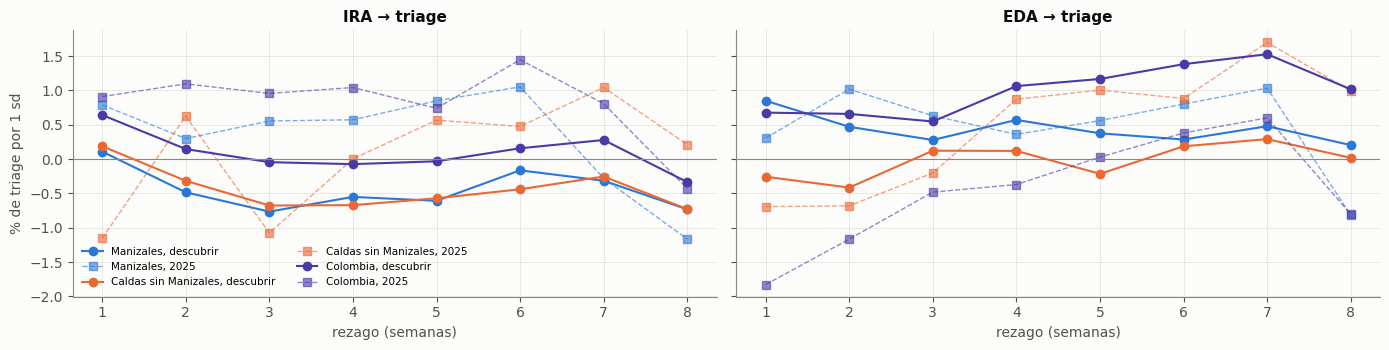

efecto % desc (rango)  p mínima desc  rezago de p mínima  efecto % 2025 en ese rezago  BH (q) de la p mínima, 48 pruebas
serie geografía                                                                                                                                    
EDA   Caldas sin Manizales         -0.42 a +0.29          0.447                   2                        -0.68                              0.937
      Colombia                     +0.55 a +1.53          0.003                   7                         0.60                              0.156
      Manizales                    +0.20 a +0.85          0.102                   1                         0.31                              0.812
IRA   Caldas sin Manizales         -0.73 a +0.19          0.226                   8                         0.21                              0.937
      Colombia                     -0.34 a +0.64          0.360                   1                         0.91                              0.937
      Manizales                    -0.77 a +0.11          0.217                   8                        -1.16                              0.937

In [15]:
filas = []
fuentes = {("IRA", "Manizales"): pares["IRA"]["Manizales"], ("IRA", "Caldas sin Manizales"): pares["IRA"]["Caldas sin Manizales"],
           ("IRA", "Colombia"): pares["IRA"]["Colombia"], ("EDA", "Manizales"): pares["EDA"]["Manizales"],
           ("EDA", "Caldas sin Manizales"): pares["EDA"]["Caldas sin Manizales"], ("EDA", "Colombia"): pares["EDA"]["Colombia"]}
for (nom, geo), a in fuentes.items():
    a = a.reindex(yv.index)
    for k in REZ[1:]:
        b, se, p, n, sdx = ajuste(yv, a, k, DESC)
        b2, _, p2, _, _ = ajuste(yv, a, k, CONF, sd=sdx)
        filas.append({"serie": nom, "geografía": geo, "rezago": k, "efecto % desc": 100 * b, "p desc": p, "efecto % 2025": 100 * b2, "p 2025": p2})
G = pd.DataFrame(filas)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for ax, nom in zip(axes, ["IRA", "EDA"]):
    for geo, col in [("Manizales", AZUL), ("Caldas sin Manizales", NARANJA), ("Colombia", VIOLETA)]:
        g = G[(G.serie == nom) & (G.geografía == geo)]
        ax.plot(g.rezago, g["efecto % desc"], marker="o", color=col, label=f"{geo}, descubrir")
        ax.plot(g.rezago, g["efecto % 2025"], marker="s", ls="--", lw=1, color=col, alpha=.6, label=f"{geo}, 2025")
    ax.axhline(0, color=MUDO, lw=.8); ax.set_title(f"{nom} → triage"); ax.set_xlabel("rezago (semanas)")
axes[0].set_ylabel("% de triage por 1 sd"); axes[0].legend(fontsize=7.5, ncol=2); plt.tight_layout(); plt.show()
res = G.groupby(["serie", "geografía"]).apply(lambda g: pd.Series({
    "efecto % desc (rango)": f"{g['efecto % desc'].min():+.2f} a {g['efecto % desc'].max():+.2f}",
    "p mínima desc": round(g["p desc"].min(), 3), "rezago de p mínima": int(g.loc[g["p desc"].idxmin(), "rezago"]),
    "efecto % 2025 en ese rezago": round(g.loc[g["p desc"].idxmin(), "efecto % 2025"], 2),
    "BH (q) de la p mínima, 48 pruebas": None}))
qG = pd.Series(multipletests(G["p desc"], method="fdr_bh")[1], index=G.index)
res["BH (q) de la p mínima, 48 pruebas"] = G.assign(q=qG).groupby(["serie", "geografía"]).q.min().round(3)
res

## Lectura del departamento frente al hospital

**Que el resto de Caldas vaya antes que Manizales no lo convierte en un indicador del hospital.** Ninguna geografía anticipa el triage total. En 48 pruebas (2 series × 3 geografías × 8 rezagos) ninguna sobrevive a BH:

- **IRA**, de cualquier geografía: entre −0,77 y +0,64 % de triage por desviación típica. Nada.
- **EDA de Colombia:** de +0,55 a +1,53 % en todos los rezagos, con p mínima de 0,003 a 7 semanas (q = 0,16) y +0,60 % en 2025 en ese rezago. Es la única con un signo constante. No llega al umbral, y siete semanas de rezago desde el país hacia un hospital local no tienen un mecanismo evidente.
- **EDA del resto de Caldas:** nada (−0,42 a +0,29 %).

**Lectura para el pronóstico.** La precedencia de Caldas sobre Manizales sirve para anticipar la IRA de la ciudad, que a su vez va con lo respiratorio del hospital (secciones 4 y 8). Es una cadena de dos eslabones y cada uno es pequeño. Si la IRA de la ciudad entrara algún día en el modelo, el resto de Caldas sería su adelanto y no un predictor aparte.

---
# 6. El rezago de publicación: qué se puede calcular a tiempo

Una serie solo sirve para **pronosticar** si su valor de la semana `t − k` ya está publicado cuando se pronostica la semana `t`. Las fuentes:

| Fuente | Rezago | Qué trae | Geografía |
|---|---|---|---|
| Microdatos del INS | **~8 meses** tras el cierre del año (2025 salió en agosto de 2026) | Todo lo de este cuaderno | Todas |
| Power BI 006 «Vigilancia rutinaria» | **~7 días**, más notificación tardía de 2-3 semanas | Eventos individuales por semana; IRA 995 total, IRAG, UCI | Manizales (descarga filtrada); el tablero tiene municipio |
| Power BI 995 «Morbilidad por IRA» | ~7 días | IRA por edad con denominador, por institución | Manizales; **nivel de +3 a +8 % sobre los microdatos** |
| Power BI por evento (300, 356, 831, 875) | ~7 días | Casos por semana | Manizales |
| BES del INS (PDF) | ~6 días | Acumulados por departamento | Caldas, extracción frágil |
| EDA 998 en Power BI | ~7 días | Existe, **no está descargado**: el filtro de municipio no se validó | — |

Consecuencias:
- **Con los microdatos no se pronostica nada:** sirven para descubrir y medir.
- Con Power BI, el último dato firme es de **2-3 semanas atrás** (la última semana llega incompleta y se corrige). Un rezago de 1 semana queda en el borde; **de 3 semanas en adelante es operativo**.
- La anomalía necesita la media del año; en operación hay que sustituirla por una media móvil hacia atrás.
- Hay **dos instantáneas** fijadas en el código de Power BI (28-09-2026 y 05-10-2026). Una instantánea por semana permitiría reconstruir qué se sabía en cada fecha.

Prueba práctica: con la instantánea del 5 de octubre de 2026 se calcula la anomalía de la IRA de Manizales para 2026 y se compara con los microdatos donde se solapan (2021-2025). También se compara con la del 28 de septiembre de 2026, para ver cuánto se reescriben las semanas recientes.

Instantáneas de Power BI: ['2026-09-28', '2026-10-05']
Entre 2026-09-28 y 2026-10-05: semanas con cambio 0 de 558; las últimas 6 semanas comunes:
fecha    2026-08-09  2026-08-16  2026-08-23  2026-08-30  2026-09-06  2026-09-13
antes           568         706         776         872         930         923
después         568         706         776         872         930         923


Power BI 995: 2015-01-04 a 2026-09-27 (560 semanas); se usan hasta 2026-09-13
Nivel Power BI / microdatos por año: {2021: 1.079, 2022: 1.056, 2023: 1.045, 2024: 1.04, 2025: 1.045}
r semanal en log, 2021-2025: 0.929
Anomalía operativa, Power BI vs microdatos, 2022-2025: r = 0.989
Anomalía operativa vs anomalía del cuaderno (con la media del año), microdatos 2022-2025: r = 0.806


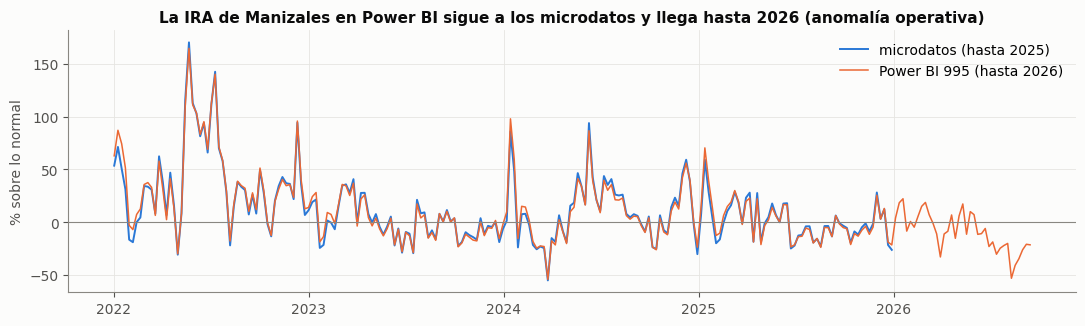

In [16]:
snaps = [RAIZ / "calendarios/vigilancia/powerbi" / f for f in ("2026-09-28", "2026-10-05")]   # capturas fijas
pbi = snaps[-1]
print("Instantáneas de Power BI:", [s.name for s in snaps])
tab = pd.read_csv(pbi / "ira_995_tablero.csv")
def inicio_se(anio, se):
    e4 = pd.Timestamp(anio, 1, 4); d1 = e4 - pd.Timedelta(days=(e4.dayofweek + 1) % 7)    # domingo de la SE1
    return d1 + pd.Timedelta(weeks=int(se) - 1)
tab["fecha"] = [inicio_se(a, s) for a, s in zip(tab.anio, tab.semana)]
ira_pbi = tab.groupby("fecha")["grup_total"].sum().sort_index()
# Cuánto se reescriben las semanas recientes entre dos instantáneas
if len(snaps) > 1:
    ant = pd.read_csv(snaps[-2] / "ira_995_tablero.csv"); ant["fecha"] = [inicio_se(a, s) for a, s in zip(ant.anio, ant.semana)]
    ira_ant = ant.groupby("fecha")["grup_total"].sum().sort_index()
    comun = ira_ant.index.intersection(ira_pbi.index)
    cambio = (ira_pbi[comun] - ira_ant[comun])
    print(f"Entre {snaps[-2].name} y {snaps[-1].name}: semanas con cambio {int((cambio != 0).sum())} de {len(comun)}; las últimas 6 semanas comunes:")
    print(pd.DataFrame({"antes": ira_ant[comun].iloc[-6:], "después": ira_pbi[comun].iloc[-6:]}).astype(int).T.to_string())
ultima = ira_pbi.index.max()
ira_pbi_firme = ira_pbi.loc[:ultima - pd.Timedelta(weeks=2)]           # las 2 ultimas se corrigen con la notificacion tardia
micro = S[("manizales", "IRA total")]
sol = pd.concat([micro.rename("micro"), ira_pbi.rename("pbi")], axis=1).dropna().loc["2021":"2025"]
print(f"Power BI 995: {ira_pbi.index.min().date()} a {ultima.date()} ({len(ira_pbi)} semanas); se usan hasta {ira_pbi_firme.index.max().date()}")
print("Nivel Power BI / microdatos por año:", (sol.groupby(sol.index.year).sum().pipe(lambda d: d.pbi / d.micro)).round(3).to_dict())
print(f"r semanal en log, 2021-2025: {np.log(sol.micro).corr(np.log(sol.pbi)):.3f}")

rej2 = pd.date_range("2015-01-04", ira_pbi_firme.index.max(), freq="W-SUN")
t2 = rej2.dayofyear.values / 365.25
F2 = pd.DataFrame({f"{n}{k}": f(2 * np.pi * k * t2) for k in (1, 2, 3) for n, f in (("s", np.sin), ("c", np.cos))}, index=rej2); F2.insert(0, "c", 1.0)
def anomalia_operativa(s, ventana=52):
    """Operativa: estación típica ajustada hasta 2024 y nivel = media móvil de las 52 semanas previas (sin mirar el futuro)."""
    l = np.log1p(s.astype(float).reindex(rej2))
    ok = l.notna().values & (~rej2.to_series().between(*COVID)).values & (rej2 <= "2024-12-31")
    lc = l - l.groupby(l.index.year).transform("mean")
    b, *_ = np.linalg.lstsq(F2.values[ok], lc.values[ok], rcond=None)
    r = l - F2.values @ b
    return r - r.shift(1).rolling(ventana, min_periods=40).mean()
op_pbi = anomalia_operativa(ira_pbi_firme)
op_micro = anomalia_operativa(micro)
print(f"Anomalía operativa, Power BI vs microdatos, 2022-2025: r = {op_pbi.loc['2022':'2025'].corr(op_micro.loc['2022':'2025']):.3f}")
print(f"Anomalía operativa vs anomalía del cuaderno (con la media del año), microdatos 2022-2025: r = "
      f"{op_micro.loc['2022':'2025'].corr(A[('manizales', 'IRA total')].reindex(rej2).loc['2022':'2025']):.3f}")
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.plot(op_micro.loc["2022":].index, 100 * (np.exp(op_micro.loc["2022":]) - 1), color=AZUL, lw=1.4, label="microdatos (hasta 2025)")
ax.plot(op_pbi.loc["2022":].index, 100 * (np.exp(op_pbi.loc["2022":]) - 1), color=NARANJA, lw=1.1, label="Power BI 995 (hasta 2026)")
ax.axhline(0, color=MUDO, lw=.8); ax.set_ylabel("% sobre lo normal"); ax.legend()
ax.set_title("La IRA de Manizales en Power BI sigue a los microdatos y llega hasta 2026 (anomalía operativa)"); plt.show()

## Lectura del rezago de publicación

**La IRA de la ciudad se puede calcular a tiempo con Power BI, y da lo mismo que los microdatos.**
- El tablero 995 cubre de 2015-01 a 2026-09-27; se descartan las 2 últimas semanas por notificación tardía y se usa hasta el 2026-09-13.
- Va entre un **4 y un 8 % por encima** de los microdatos todos los años (1,040 a 1,079), como indica la auditoría de la fuente. Es un nivel y la anomalía lo quita.
- La **anomalía operativa** (estación típica hasta 2024 y nivel igual a la media de las 52 semanas previas, sin mirar el futuro) calculada con Power BI correlaciona **0,989** con la calculada con microdatos.
- Frente a la anomalía de este cuaderno (media del año entero) correlaciona **0,806**: pasar a la versión operativa **no es gratis**. Un resultado obtenido con la anomalía de las secciones 2 a 5 hay que volver a medirlo con la operativa antes de usarlo para pronosticar, que es lo que hacen las secciones 7 a 9.
- Entre las dos instantáneas del tablero 995, separadas por una semana, no cambió ninguna de las 558 semanas comunes, de modo que con este par no se observó la reescritura de las semanas recientes que describe la fuente. La reescritura sí es conocida en el tablero de vigilancia rutinaria.
- En 2026 la IRA de la ciudad va, casi todo el año, **por debajo** de lo normal (figura).

**Qué se puede calcular a tiempo y qué no:**

| Serie | ¿A tiempo? | Cómo |
|---|---|---|
| IRA de Manizales por edad (el grueso de PC1) | **Sí**, con 2-3 semanas de margen | Power BI 995, congelado cada semana |
| IRAG hospitalización y UCI de Manizales | Sí, en total | Power BI 006 (`ira_995_rutinaria`) |
| Eventos individuales de Manizales | Sí | Power BI 006 y tableros por evento |
| EDA 998 de Manizales (y con ella PC2) | **No por ahora**: el tablero existe y no está descargado | Requiere validar el filtro de municipio |
| Caldas sin Manizales, Colombia | **No con lo congelado** (solo Manizales) | El tablero 995 trae el municipio de cada institución |
| Cualquier cosa con microdatos | **No**: ~8 meses de retraso | Solo para descubrir y medir |

**Límite.** Con dos instantáneas no se sabe qué valor se conocía en cada fecha pasada. Una evaluación de pronóstico honesta requiere la serie completa de instantáneas semanales.

---
# 7. Las olas como episodios

**Por qué se repite la medición.** Las secciones 2 a 4 tratan la vigilancia como un nivel continuo contra el triage total. Una ola respiratoria o diarreica, en cambio, es un episodio: empieza, dura unas semanas y termina, y puede ocurrir en la misma época todos los años. Medirla con una regresión sobre 147 semanas promedia los episodios con las semanas tranquilas y deja el efecto sin separar de la estación. Aquí se la trata como lo que es.

**Definición, fijada antes de leer los resultados.** El índice de cada familia de enfermedad es el de `indices.py`: promedio de las anomalías operativas estandarizadas de sus series (respiratoria: IRA total, IRA 0-4, IRA 60+ e IRAG hospitalizada; digestiva: EDA total y EDA 0-4; violencias y agresiones; salud mental e intoxicaciones; materno-perinatal; inmunoprevenibles). Se reestandariza con la media y la desviación de descubrir. **Una ola es una racha de semanas con el índice igual o mayor que 1 desviación típica**, y un hueco de una semana no la parte. Se ajustan los desenlaces por banda de edad con el mismo tratamiento que `y` (sin calendario, sin nivel del año ni de la red).

Dos precisiones sobre el peso de lo respiratorio: los diagnósticos respiratorios son una fracción pequeña del triage, y el triage de 0 a 4 años y el de 5 a 14 son el 3,2 % y el 4,8 % del total, mientras que el de 15 a 44 es el 54,5 %. Una ola que actúe sobre niños se diluye en el total por construcción.

In [17]:
import indices as ix
import desenlace as DS
# Desenlaces por banda de edad, con el mismo tratamiento que el desenlace total (sin calendario, sin nivel del año ni de la red)
dias_h = pd.date_range("2020-01-01", "2026-09-19")
te = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet"); te["dia"] = pd.to_datetime(te["dia"])
tot_d = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia)).set_index("dia")["triages"].reindex(dias_h).astype(float)
tot_d["2024-03-19":"2024-03-21"] = np.nan                    # caída del registro: nulo, no cero
completas = DS._semana(tot_d.notna().astype(int)) == 7
cal_d = (pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
           .reindex(dias_h)[DS.CAL].apply(pd.to_numeric, errors="coerce").fillna(0))
cal_w = DS._semana(cal_d).loc[DS.INICIO:DS.FIN]
BANDAS_T = ["0-4", "5-14", "15-44", "45-64", "65-+"]
tri_banda, res_banda = {}, {}
for b in BANDAS_T:
    s = te[te.banda.eq(b)].set_index("dia")["n"].reindex(dias_h).fillna(0).astype(float)   # el GROUP BY no emite ceros
    s[tot_d.isna()] = np.nan
    w = DS._semana(s).where(completas)
    tri_banda[b] = w
    res_banda[f"triage {b}"] = DS._residuo(w.loc[DS.INICIO:DS.FIN], cal_w)
TRI_BANDA = pd.DataFrame(tri_banda)
SEMANAL = pd.concat([Y[["y", "y_respiratorio", "y_infecciosas", "y_trauma"]].rename(columns={
                        "y": "triage total", "y_respiratorio": "dx respiratorio", "y_infecciosas": "dx infecciosas", "y_trauma": "dx trauma"}),
                     pd.DataFrame(res_banda)], axis=1).reindex(yv.index)
SEMANAL_SIN = SEMANAL.apply(sin_estacion)           # los mismos desenlaces sin su forma estacional (3 armónicos ajustados en descubrir)

# Cuánto pesa lo respiratorio dentro del triage total
dx = pd.read_parquet(RAIZ / "salidas/perfil_dx_diario.parquet"); dx["dia"] = pd.to_datetime(dx["dia"])
resp_d = dx[dx.capitulo.eq("X Respiratorio")].set_index("dia")["n"].reindex(dias_h).fillna(0).astype(float)
resp_d[tot_d.isna()] = np.nan
resp_w, tot_w = DS._semana(resp_d).where(completas), DS._semana(tot_d).where(completas)
peso_resp = (100 * resp_w / tot_w).groupby(resp_w.index.year).mean().loc[2022:2025].round(1)
print("Diagnósticos respiratorios como % del triage total (media por año):", peso_resp.to_dict())
print("Parte de cada banda en el triage semanal (media 2022-2025, %):",
      (100 * TRI_BANDA.loc["2022":"2025"].mean() / TRI_BANDA.loc["2022":"2025"].sum(axis=1).mean()).round(1).to_dict())

# Índice de cada familia de enfermedad (anomalía operativa, estandarizada con la desviación de descubrir)
FAM = ix.familias_enfermedad()
ZF = FAM.copy()
for c in FAM:
    ZF[c] = (FAM[c] - FAM[c].loc[DESC[0]:DESC[1]].mean()) / FAM[c].loc[DESC[0]:DESC[1]].std()
ZF = ZF.reindex(yv.index)
print("Familias:", list(ZF.columns))

Diagnósticos respiratorios como % del triage total (media por año): {2022: 3.5, 2023: 4.1, 2024: 2.5, 2025: 2.0}
Parte de cada banda en el triage semanal (media 2022-2025, %): {'0-4': 3.2, '5-14': 4.8, '15-44': 54.5, '45-64': 18.5, '65-+': 19.4}


Familias: ['respiratoria', 'digestiva', 'violencias_y_agresiones', 'salud_mental_e_intoxicaciones', 'materno_perinatal', 'inmunoprevenibles']


In [18]:
def episodios(z, umbral=1.0, hueco=1, periodo=("2022-03-06", "2025-12-28")):
    """Semanas consecutivas con el índice >= umbral; un hueco de hasta `hueco` semanas no parte el episodio."""
    on = (z >= umbral).loc[periodo[0]:periodo[1]]
    eps, ini, ult = [], None, None
    for f, v in on.items():
        if not v: continue
        if ini is None: ini = f
        elif (f - ult).days > 7 * (hueco + 1): eps.append((ini, ult)); ini = f
        ult = f
    if ini is not None: eps.append((ini, ult))
    return eps
EP = {c: episodios(ZF[c]) for c in ZF}
filas = []
for c, eps in EP.items():
    en_ola = pd.Series(False, index=ZF.index)
    for a, b in eps: en_ola[a:b] = True
    filas.append({"familia": c.replace("_", " "), "episodios": len(eps), **{f"episodios {y}": int(sum(a.year == y for a, _ in eps)) for y in (2022, 2023, 2024, 2025)},
                  "semanas en ola": int(en_ola.sum()), "duración máxima (sem.)": max([int((b - a).days / 7 + 1) for a, b in eps], default=0)})
print("Ola = índice de la familia >= 1 desviación típica (de descubrir); un hueco de 1 semana no parte el episodio. 2022-03 a 2025-12.")
display(pd.DataFrame(filas).set_index("familia"))
ola_resp = pd.DataFrame([{"inicio": a.date(), "semanas": int((b - a).days / 7 + 1), "pico del índice (sd)": round(ZF.respiratoria.loc[a:b].max(), 2)} for a, b in EP["respiratoria"]])
ola_resp

Ola = índice de la familia >= 1 desviación típica (de descubrir); un hueco de 1 semana no parte el episodio. 2022-03 a 2025-12.


,episodios,episodios 2022,episodios 2023,episodios 2024,episodios 2025,semanas en ola,duración máxima (sem.)
familia,,,,,,,
respiratoria,5,2,0,2,1,26,11
digestiva,12,2,6,3,1,30,5
violencias y agresiones,18,6,5,3,4,31,6
salud mental e intoxicaciones,22,5,6,6,5,34,8
materno perinatal,21,6,5,7,3,32,4
inmunoprevenibles,15,5,5,2,3,28,6


,inicio,semanas,pico del índice (sd)
0,2022-05-15,11,3.01
1,2022-12-11,1,1.38
2,2024-01-14,2,1.82
3,2024-05-19,10,2.36
4,2025-06-08,2,1.31


## Lectura de los episodios

**Las olas respiratorias son pocas y largas; las de las demás familias son muchas y breves.** En 2022-03 a 2025-12 hay 5 episodios respiratorios, 26 semanas de 200. Dos son olas de verdad: la que empieza el 15 de mayo de 2022 (11 semanas, pico de 3,0 desviaciones típicas) y la del 19 de mayo de 2024 (10 semanas, pico de 2,4). Los otros tres duran 1 o 2 semanas. En 2023 no hubo ninguna y en 2025 solo una de 2 semanas. En las demás familias hay entre 12 y 22 episodios, casi todos de una semana, que son el ruido de series con pocos casos por semana más que olas.

Esto concuerda con lo que se vio al entrenar el pronóstico: la marca de «ola de salud pública», construida con todas las familias, cubrió 35 días en 2023 y 70 en 2024, y apenas 7 en 2025 y 0 en 2026. Los años recientes casi no tienen olas, de modo que cualquier método tiene pocos episodios con los que aprender.

**Límite.** Con 5 episodios respiratorios, y solo dos largos, ningún estadístico por episodio tiene potencia. Lo que sigue es una descripción de lo que ocurrió en esos episodios más una regresión sobre las semanas en ola, no una estimación precisa.

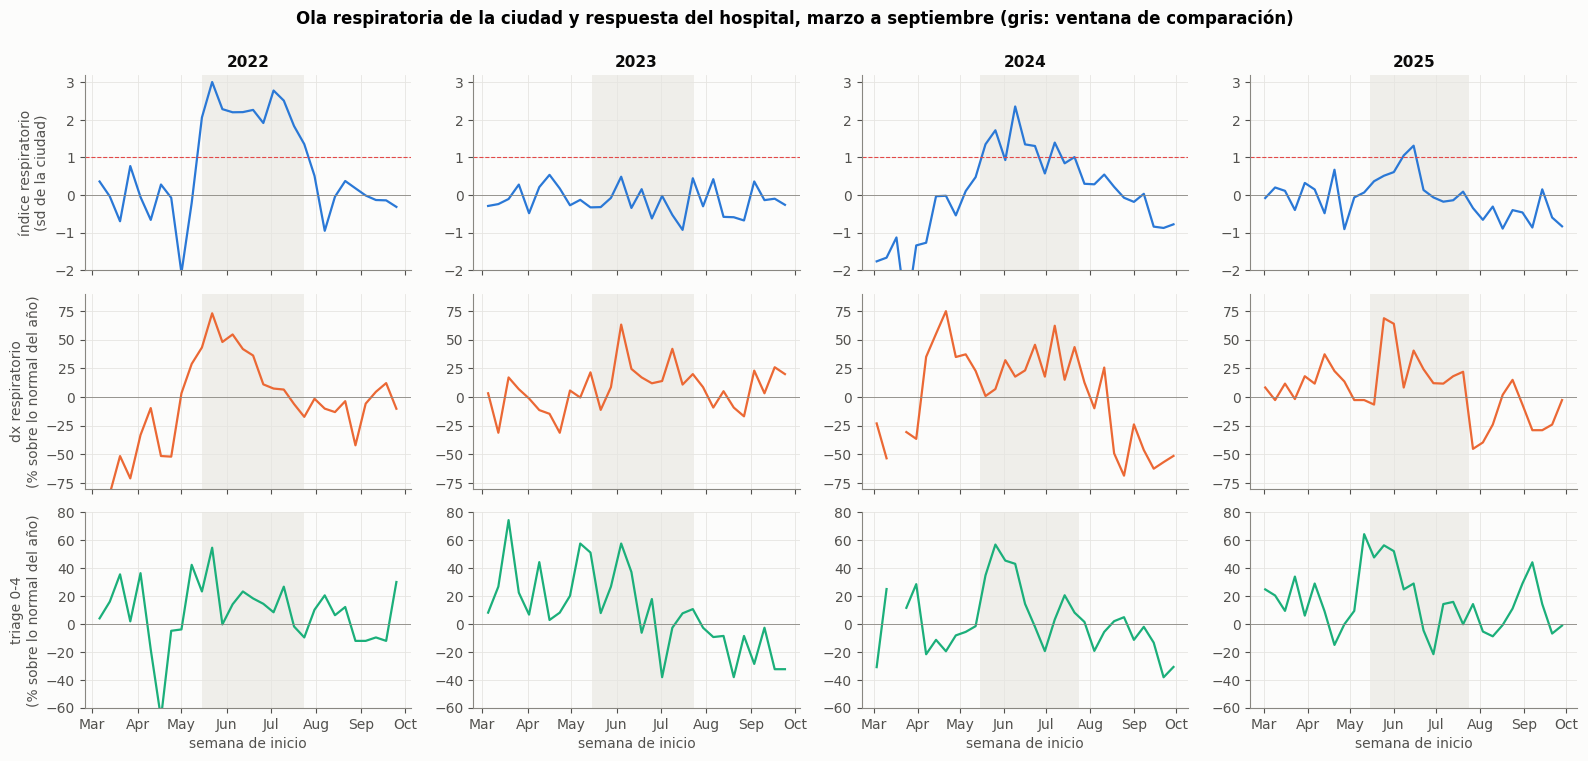

año,2022,2023,2024,2025
semanas con índice >= 1,11.00,0.00,7.00,2.00
índice respiratorio medio (sd),2.22,-0.18,1.28,0.37
dx respiratorio,27.10,20.10,26.50,26.20
triage 0-4,15.60,11.90,20.60,21.40
triage 5-14,6.20,13.80,7.20,9.80
triage 65-+,7.70,-1.30,8.10,1.40
triage total,6.90,3.40,4.70,3.50


In [19]:
import matplotlib.dates as mdates
# Misma época, años con ola y años sin ola: del 15 de mayo al 24 de julio
filas = []
for a in (2022, 2023, 2024, 2025):
    sl = slice(pd.Timestamp(a, 5, 15), pd.Timestamp(a, 7, 24))
    filas.append({"año": a, "semanas con índice >= 1": int((ZF.respiratoria.loc[sl] >= 1).sum()),
                  "índice respiratorio medio (sd)": round(ZF.respiratoria.loc[sl].mean(), 2),
                  **{c: round(100 * SEMANAL[c].loc[sl].mean(), 1) for c in ["dx respiratorio", "triage 0-4", "triage 5-14", "triage 65-+", "triage total"]}})
VENT = pd.DataFrame(filas).set_index("año")
fig, axes = plt.subplots(3, 4, figsize=(16, 7.6), sharex="col")
for j, a in enumerate((2022, 2023, 2024, 2025)):
    sl = slice(pd.Timestamp(a, 3, 1), pd.Timestamp(a, 9, 30))
    z = ZF.respiratoria.loc[sl]
    for i, (c, col) in enumerate([(None, AZUL), ("dx respiratorio", NARANJA), ("triage 0-4", AQUA)]):
        ax = axes[i, j]
        if c is None:
            ax.plot(z.index, z.values, color=col, lw=1.6); ax.axhline(1, color=ROJO, lw=.8, ls="--"); ax.axhline(0, color=MUDO, lw=.6)
            ax.set_ylim(-2, 3.2)
            if j == 0: ax.set_ylabel("índice respiratorio\n(sd de la ciudad)")
        else:
            v = SEMANAL[c].loc[sl]; ax.plot(v.index, 100 * v.values, color=col, lw=1.6); ax.axhline(0, color=MUDO, lw=.6)
            ax.set_ylim(-80, 90) if i == 1 else ax.set_ylim(-60, 80)
            if j == 0: ax.set_ylabel(f"{c}\n(% sobre lo normal del año)")
        ax.axvspan(pd.Timestamp(a, 5, 15), pd.Timestamp(a, 7, 24), color="#efeeea", lw=0)
        if i == 0: ax.set_title(str(a))
        if i == 2: ax.xaxis.set_major_formatter(mdates.DateFormatter("%b")); ax.set_xlabel("semana de inicio")
plt.suptitle("Ola respiratoria de la ciudad y respuesta del hospital, marzo a septiembre (gris: ventana de comparación)", fontweight="bold", y=.995)
plt.tight_layout(); plt.show()
VENT.T

## Lectura de la comparación en la misma época

La figura pone, año por año, el índice respiratorio de la ciudad, los diagnósticos respiratorios del hospital y el triage de 0 a 4 años. La banda gris es la ventana del 15 de mayo al 24 de julio, la época en que el índice supera 1 desviación típica en 2022 y en 2024.

**La época explica casi todo lo respiratorio del hospital, haya o no ola.** En esa ventana los diagnósticos respiratorios están entre +20,1 y +27,1 % sobre lo normal del año en los cuatro años, incluido 2023, sin ninguna semana con el índice igual o mayor que 1. La diferencia entre los años con ola (2022: +27,1 %; 2024: +26,5 %) y 2023 (+20,1 %) es de 6 a 7 puntos, y 2025, con 2 semanas en ola, queda en +26,2 %.

**En las edades extremas y en el total la ola sí deja una diferencia, aunque pequeña.** El triage de 65 años o más pasa de −1,3 % en 2023 y +1,4 % en 2025 a +7,7 % en 2022 y +8,1 % en 2024. El triage total pasa de +3,4 % y +3,5 % en los años sin ola a +6,9 % y +4,7 % en los años con ola. En 0 a 4 años no se ve: 2023 queda en +11,9 %, pero 2025, con casi nada de ola, queda en +21,4 %, por encima de 2022 (+15,6 %). En 5 a 14 años ocurre lo contrario: 2023 es el año más alto (+13,8 %).

**Interpretación.** Son cuatro años y una sola comparación por año: lo que se lee es una pista sobre mayores y total, no una prueba. Muestra además que el índice de la ciudad no resume todo lo que mueve el triage infantil, porque en 2025 el triage de 0 a 4 estuvo alto con una ola casi ausente. Las desviaciones respecto del año son residuos con el calendario y el nivel quitados; no son porcentajes de pacientes.

In [20]:
# Efecto de «estar en ola»: indicador semanal de ola respiratoria, rezagos 0-3, 2022-03 a 2025-12 (hay pocas olas: se juntan los periodos)
ola = pd.Series(0.0, index=yv.index)
for a, b in EP["respiratoria"]: ola[a:b] = 1.0
filas = []
for out in ["dx respiratorio", "triage 0-4", "triage 65-+", "triage total"]:
    for tag, base in (("con estación", SEMANAL), ("sin estación", SEMANAL_SIN)):
        for k in range(0, 4):
            d = pd.DataFrame({"y": base[out], "x": ola.shift(k)}).loc["2022-03-06":"2025-12-28"].dropna()
            m = sm.OLS(d.y, sm.add_constant(d.x)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
            filas.append({"desenlace": out, "estación": tag, "rezago": k, "efecto % en ola": 100 * m.params["x"], "p": m.pvalues["x"]})
OLA = pd.DataFrame(filas)
OLA["q"] = multipletests(OLA.p, method="fdr_bh")[1]
print(f"Semanas en ola respiratoria: {int(ola.sum())} de {len(ola.loc['2022-03-06':'2025-12-28'])} | episodios: {len(EP['respiratoria'])} | pruebas: {len(OLA)}")
OLA.pivot_table(index=["desenlace", "estación"], columns="rezago", values="efecto % en ola").round(1).join(
    OLA.assign(cuenta=OLA.q < .10).groupby(["desenlace", "estación"]).cuenta.sum().rename("pruebas con q < 0,10"))

Semanas en ola respiratoria: 26 de 200 | episodios: 5 | pruebas: 32


0     1     2     3  pruebas con q < 0,10
desenlace       estación                                                  
dx respiratorio con estación  35.4  31.1  21.4  14.6                     3
                sin estación   7.6   6.3   0.8  -1.0                     0
triage 0-4      con estación  21.2  13.0   5.8   6.1                     2
                sin estación   6.5  -0.3  -5.6  -3.1                     0
triage 65-+     con estación   7.9   6.7   7.5   7.0                     4
                sin estación   2.4   1.0   1.9   1.5                     0
triage total    con estación   6.2   4.5   3.1   2.5                     3
                sin estación   1.5   0.1  -0.9  -1.2                     0

## Lectura de la regresión sobre las semanas en ola

Con el desenlace tal como es (con estación), **estar en ola respiratoria acompaña a +35,4 % de diagnósticos respiratorios la misma semana y +31,1 % una semana después**, y a +21,2 % y +13,0 % de triage de 0 a 4 años. En el triage de 65 años o más el efecto es de +6,7 a +7,9 %, y en el triage total de +2,5 a +6,2 %. De las 16 pruebas con estación, 12 sobreviven a Benjamini-Hochberg.

**Con el desenlace sin su estación no sobrevive ninguna de las 16.** Los diagnósticos respiratorios quedan en +7,6 % y +6,3 % (rezagos 0 y 1) y el triage total en +1,5 % y +0,1 %.

Hay dos lecturas posibles y con estos datos no se pueden separar. Una es que las olas de la ciudad no añaden nada a lo que ya hace la estación. La otra es que **las dos olas largas ocurren en la misma época en 2022 y en 2024, y el ajuste de tres armónicos sobre solo tres años de descubrir absorbe parte del propio efecto de la ola**, de modo que quitar la estación del desenlace quita también la señal. La comparación en la misma época deja una diferencia pequeña en los mayores y en el total, compatible con un efecto real, y casi ninguna en lo respiratorio hospitalario, donde la época lo explica todo. La conclusión que sostienen los datos es: **el efecto de las olas respiratorias sobre el hospital no se puede separar de la época del año con tres años de episodios**.

**Límite.** Un indicador de ola con 26 semanas positivas agrupadas en 5 episodios tiene una muestra efectiva mucho menor que 200 semanas. Los errores HAC corrigen la autocorrelación pero no la escasez de episodios.

---
# 8. El efecto por banda de edad

**Por qué por banda de edad.** La IRA de la ciudad es en su mayor parte infantil y escolar, mientras que el triage total es en más de la mitad de adultos de 15 a 44 años. Si el factor actúa sobre una banda, comparar con el total diluye el efecto en las demás. En una medición previa, la IRA de 0 a 4 años de Manizales y el triage de 0 a 4 años del hospital dieron r = 0,70 en conteos y 0,81 con cada año contra su propia media.

**Diseño, fijado antes de leer los resultados.** Diez pares de banda de edad: las cinco bandas de IRA contra las cinco bandas de triage (0-4 con 0-4, 5-19 con 5-14, 20-39 con 15-44, 40-59 con 45-64 y 60 o más con 65 o más) y las cinco de EDA contra las mismas. Anomalía **operativa** (media de las 52 semanas previas, la que existe al pronosticar), rezagos de 0 a 8 semanas, descubrir 2022-03 a 2024-12 y confirmación en 2025. Benjamini-Hochberg con q = 0,10 sobre las 90 pruebas. Cada resultado se lleva también al desenlace sin estación y a la prueba de rezagos negativos.

In [21]:
# Anomalía operativa por banda de edad (media de las 52 semanas previas) y pares banda de IRA o EDA -> banda del triage
BANDAS_EDAD = ["IRA 0-4", "IRA 5-19", "IRA 20-39", "IRA 40-59", "IRA 60+", "EDA 0-4", "EDA 5-14", "EDA 15-44", "EDA 45-64", "EDA 65+"]
AO = {n: ix.anomalia_operativa(S[("manizales", n)].reindex(rejilla)) for n in BANDAS_EDAD}
PARES_EDAD = [("IRA 0-4", "triage 0-4"), ("IRA 5-19", "triage 5-14"), ("IRA 20-39", "triage 15-44"), ("IRA 40-59", "triage 45-64"), ("IRA 60+", "triage 65-+"),
              ("EDA 0-4", "triage 0-4"), ("EDA 5-14", "triage 5-14"), ("EDA 15-44", "triage 15-44"), ("EDA 45-64", "triage 45-64"), ("EDA 65+", "triage 65-+")]
# Reproducción de la correlación en conteos: 2020-2025, 312 semanas
c04 = pd.concat([TRI_BANDA["0-4"].rename("t"), S[("manizales", "IRA 0-4")].rename("i")], axis=1).loc["2020":"2025"].dropna()
c04n = c04 / c04.groupby(c04.index.year).transform("mean")
print(f"IRA 0-4 de Manizales contra triage 0-4, {len(c04)} semanas de 2020-2025: r = {c04.t.corr(c04.i):.3f} en conteos y {c04n.t.corr(c04n.i):.3f} con cada año contra su media")
print(f"Con la IRA una semana antes: r = {np.corrcoef(c04.t.iloc[1:], c04.i.iloc[:-1])[0, 1]:.3f}")
def unilateral(b, b0, p): return np.where(np.sign(b) == np.sign(b0), p / 2, 1 - p / 2)
filas = []
for x, out in PARES_EDAD:
    xx = AO[x].reindex(yv.index)
    for k in REZ:
        b, se, p, n, sdx = ajuste(SEMANAL[out], xx, k, DESC)
        b2, _, p2, _, _ = ajuste(SEMANAL[out], xx, k, CONF, sd=sdx)
        bs, _, ps, _, sds = ajuste(SEMANAL_SIN[out], xx, k, DESC)
        bs2, _, ps2, _, _ = ajuste(SEMANAL_SIN[out], xx, k, CONF, sd=sds)
        filas.append({"serie": x, "banda del triage": out, "rezago": k, "efecto %": 100 * b, "p": p, "efecto % 2025": 100 * b2, "p 2025": p2,
                      "sin estación: efecto %": 100 * bs, "sin estación: p": ps, "sin estación: efecto % 2025": 100 * bs2, "sin estación: p 2025": ps2})
EDAD = pd.DataFrame(filas)
EDAD["q"] = multipletests(EDAD.p, method="fdr_bh")[1]
EDAD["q sin estación"] = multipletests(EDAD["sin estación: p"], method="fdr_bh")[1]
EDAD["p unilateral 2025"] = unilateral(EDAD["efecto % 2025"], EDAD["efecto %"], EDAD["p 2025"])
EDAD["sin estación: p unilateral 2025"] = unilateral(EDAD["sin estación: efecto % 2025"], EDAD["sin estación: efecto %"], EDAD["sin estación: p 2025"])
print(f"Pruebas: {len(EDAD)} | p < 0,05: {(EDAD.p < .05).sum()} (azar: {.05 * len(EDAD):.1f}) | sobreviven a BH: {(EDAD.q < .10).sum()} "
      f"| con el desenlace sin estación: {(EDAD['q sin estación'] < .10).sum()}")
sob = EDAD[(EDAD.q < .10) | (EDAD["q sin estación"] < .10)]
sob[["serie", "banda del triage", "rezago", "efecto %", "q", "p unilateral 2025", "efecto % 2025", "sin estación: efecto %", "q sin estación",
     "sin estación: efecto % 2025", "sin estación: p unilateral 2025"]].round(3).reset_index(drop=True)

IRA 0-4 de Manizales contra triage 0-4, 312 semanas de 2020-2025: r = 0.703 en conteos y 0.808 con cada año contra su media
Con la IRA una semana antes: r = 0.651


Pruebas: 90 | p < 0,05: 14 (azar: 4.5) | sobreviven a BH: 6 | con el desenlace sin estación: 1


,serie,banda del triage,rezago,efecto %,q,p unilateral 2025,efecto % 2025,sin estación: efecto %,q sin estación,sin estación: efecto % 2025,sin estación: p unilateral 2025
0,IRA 0-4,triage 0-4,0,9.197,0.000,0.000,30.493,3.607,0.239,21.368,0.001
1,IRA 0-4,triage 0-4,1,7.311,0.030,0.000,26.441,2.199,0.537,17.938,0.005
2,IRA 5-19,triage 5-14,0,7.517,0.031,0.025,12.133,5.098,0.239,9.575,0.043
3,IRA 60+,triage 65-+,0,2.949,0.031,0.613,-0.526,1.045,0.498,-2.758,0.895
4,IRA 60+,triage 65-+,1,2.638,0.058,0.890,-1.980,0.786,0.552,-4.045,0.987
5,EDA 15-44,triage 15-44,0,1.991,0.012,0.432,0.178,1.811,0.019,0.526,0.291


## Lectura del barrido por banda

**La correlación de la IRA infantil con el triage de su edad se reproduce: r = 0,703 en conteos y 0,808 con cada año contra su media, en 312 semanas de 2020 a 2025.** Con la IRA una semana antes, r = 0,651. Es una correlación en niveles, con dos años de COVID dentro, y por sí sola dice poco sobre rezagos.

De las 90 pruebas, **14 tienen p < 0,05 (el azar daría 4,5) y 6 sobreviven a BH**:

| Serie → banda del triage | Rezago | Descubrir | 2025 | Lectura |
|---|---|---|---|---|
| **IRA 0-4 → triage 0-4** | 0 | +9,2 % por sd | +30,5 % (p unilateral < 0,001) | **Se confirma** |
| **IRA 0-4 → triage 0-4** | 1 | +7,3 % | +26,4 % (p unilateral < 0,001) | **Se confirma** |
| **IRA 5-19 → triage 5-14** | 0 | +7,5 % | +12,1 % (p unilateral 0,025) | **Se confirma** |
| IRA 60+ → triage 65+ | 0 y 1 | +2,9 % y +2,6 % | −0,5 % y −2,0 % | No se confirma |
| EDA 15-44 → triage 15-44 | 0 | +2,0 % | +0,2 % | No se confirma |

- **Por edad el efecto aparece donde debía.** El triage de 0 a 4 años se mueve +9,2 % por desviación típica de la IRA infantil, y el de 5 a 14, +7,5 % por la IRA escolar. Frente al total (menos de ±2 %), el efecto es varias veces mayor.
- **La dilución se puede calcular con estas mismas cifras.** El triage de 0 a 4 años es el 3,2 % del total: un +9,2 % en esa banda equivale a unos +0,3 % en el total, lo que es compatible con que el total no muestre nada.
- **En los mayores no se sostiene.** La IRA de 60 años o más da +2,9 % en descubrir, pero en 2025 el signo se invierte.
- **El tamaño en 2025 es de dos a tres veces el de descubrir** (+30,5 % frente a +9,2 % en la IRA 0-4). Con 52 semanas no se puede decir si el vínculo se reforzó o si es ruido de una muestra corta; el signo y la significación sí se repiten.
- **Con el desenlace sin estación, solo la EDA 15-44 sobrevive a BH en descubrir, y no se confirma.** La IRA 0-4 y la IRA 5-19 conservan el signo (+3,6 % y +5,1 % en descubrir a rezago 0) y siguen siendo significativas en 2025 (+21,4 % y +9,6 %; p unilateral 0,001 y 0,043), pero sin estación no pasan la corrección en descubrir (q de 0,24 a 0,54). Es el mismo límite de la sección 7: los años de descubrir son pocos para separar la estación de la ola.

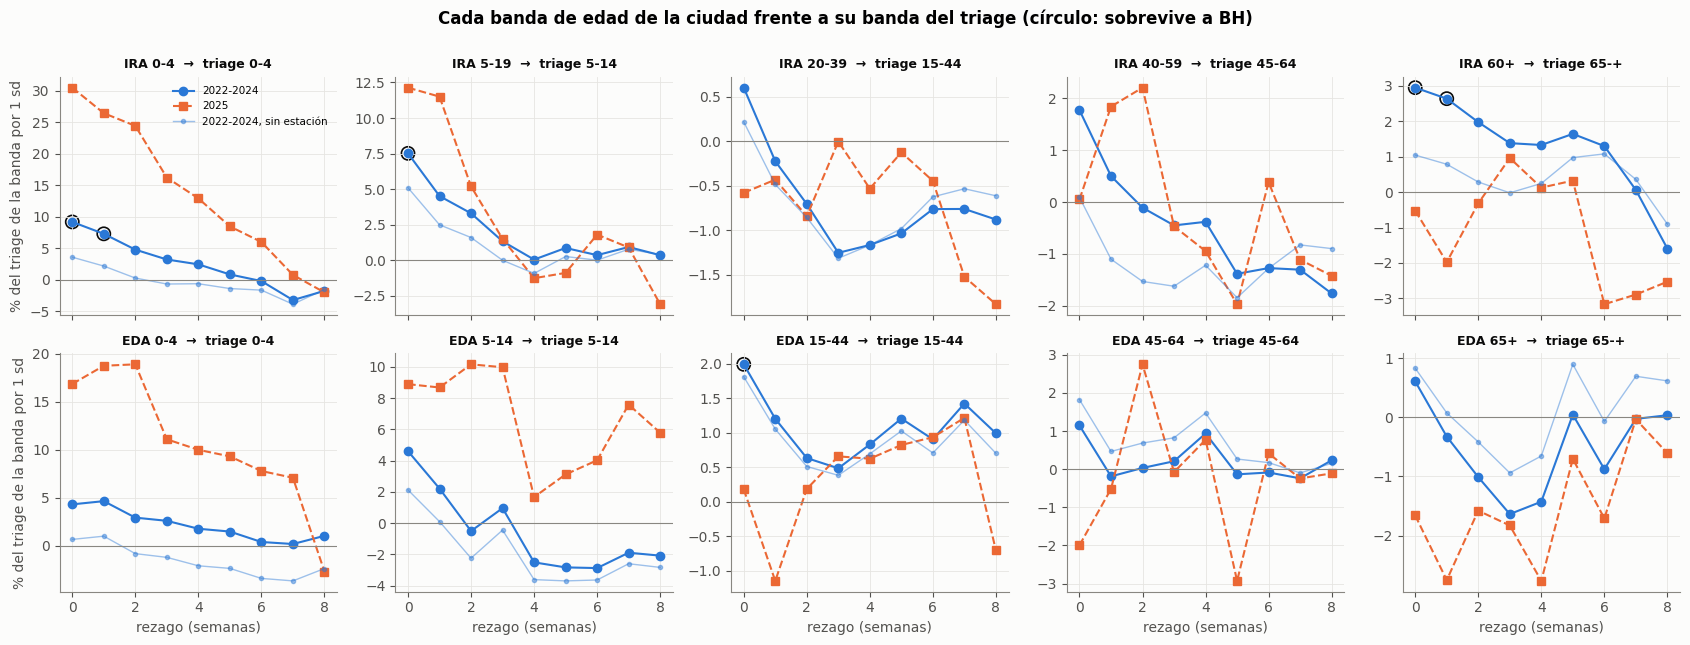

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6.4), sharex=True)
for i, (x, out) in enumerate(PARES_EDAD):
    ax = axes[i // 5, i % 5]; g = EDAD[(EDAD.serie == x) & (EDAD["banda del triage"] == out)]
    ax.plot(g.rezago, g["efecto %"], marker="o", color=AZUL, label="2022-2024")
    ax.plot(g.rezago, g["efecto % 2025"], marker="s", ls="--", color=NARANJA, label="2025")
    ax.plot(g.rezago, g["sin estación: efecto %"], marker="o", ms=3, lw=1, color=AZUL, alpha=.45, label="2022-2024, sin estación")
    s_ = g[g.q < .10]; ax.scatter(s_.rezago, s_["efecto %"], s=90, facecolors="none", edgecolors=TINTA, lw=1.2)
    ax.axhline(0, color=MUDO, lw=.8); ax.set_title(f"{x}  →  {out}", fontsize=9)
    if i // 5 == 1: ax.set_xlabel("rezago (semanas)")
    if i % 5 == 0: ax.set_ylabel("% del triage de la banda por 1 sd")
axes[0, 0].legend(fontsize=7.5)
plt.suptitle("Cada banda de edad de la ciudad frente a su banda del triage (círculo: sobrevive a BH)", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

In [23]:
# Efecto por rezago (% por sd) de cada par, para leer los valores de la figura
perfil = {}
for x, out in PARES_EDAD:
    g = EDAD[(EDAD.serie == x) & (EDAD["banda del triage"] == out)].set_index("rezago")
    perfil[(f"{x} → {out}", "2022-24")] = g["efecto %"]; perfil[(f"{x} → {out}", "2025")] = g["efecto % 2025"]; perfil[(f"{x} → {out}", "sin estación")] = g["sin estación: efecto %"]
pd.DataFrame(perfil).T.round(1)

rezago                                    0     1     2     3     4    5    6    7    8
IRA 0-4 → triage 0-4     2022-24        9.2   7.3   4.8   3.2   2.5  0.9 -0.2 -3.2 -1.7
                         2025          30.5  26.4  24.4  16.2  12.9  8.5  6.0  0.8 -2.0
                         sin estación   3.6   2.2   0.3  -0.6  -0.6 -1.4 -1.6 -3.9 -1.5
IRA 5-19 → triage 5-14   2022-24        7.5   4.5   3.3   1.3   0.1  0.9  0.4  0.9  0.4
                         2025          12.1  11.5   5.2   1.5  -1.3 -0.9  1.8  0.9 -3.1
                         sin estación   5.1   2.5   1.6   0.0  -0.9  0.3  0.0  0.8  0.4
IRA 20-39 → triage 15-44 2022-24        0.6  -0.2  -0.7  -1.3  -1.2 -1.0 -0.8 -0.8 -0.9
                         2025          -0.6  -0.4  -0.8  -0.0  -0.5 -0.1 -0.4 -1.5 -1.8
                         sin estación   0.2  -0.5  -0.9  -1.3  -1.2 -1.0 -0.6 -0.5 -0.6
IRA 40-59 → triage 45-64 2022-24        1.8   0.5  -0.1  -0.5  -0.4 -1.4 -1.3 -1.3 -1.8
                         2025           0.0   1.8   2.2  -0.5  -0.9 -2.0  0.4 -1.1 -1.4
                         sin estación   0.1  -1.1  -1.5  -1.6  -1.2 -1.8 -1.3 -0.8 -0.9
IRA 60+ → triage 65-+    2022-24        2.9   2.6   2.0   1.4   1.3  1.6  1.3  0.1 -1.6
                         2025          -0.5  -2.0  -0.3   1.0   0.1  0.3 -3.2 -2.9 -2.5
                         sin estación   1.0   0.8   0.3  -0.0   0.2  1.0  1.1  0.4 -0.9
EDA 0-4 → triage 0-4     2022-24        4.3   4.7   2.9   2.6   1.8  1.5  0.4  0.2  1.0
                         2025          16.8  18.7  18.9  11.1  10.0  9.3  7.8  7.1 -2.7
                         sin estación   0.7   1.0  -0.8  -1.2  -2.1 -2.3 -3.4 -3.6 -2.4
EDA 5-14 → triage 5-14   2022-24        4.6   2.2  -0.5   1.0  -2.5 -2.8 -2.9 -1.9 -2.1
                         2025           8.9   8.7  10.2  10.0   1.7  3.1  4.0  7.6  5.8
                         sin estación   2.1   0.1  -2.2  -0.4  -3.6 -3.7 -3.6 -2.6 -2.8
EDA 15-44 → triage 15-44 2022-24        2.0   1.2   0.6   0.5   0.8  1.2  0.9  1.4  1.0
                         2025           0.2  -1.1   0.2   0.7   0.6  0.8  0.9  1.2 -0.7
                         sin estación   1.8   1.1   0.5   0.4   0.7  1.0  0.7  1.2  0.7
EDA 45-64 → triage 45-64 2022-24        1.1  -0.2   0.0   0.2   0.9 -0.1 -0.1 -0.2  0.2
                         2025          -2.0  -0.5   2.8  -0.1   0.8 -2.9  0.4 -0.2 -0.1
                         sin estación   1.8   0.5   0.7   0.8   1.5  0.3  0.2 -0.1  0.2
EDA 65+ → triage 65-+    2022-24        0.6  -0.3  -1.0  -1.6  -1.4  0.0 -0.9 -0.0  0.0
                         2025          -1.7  -2.8  -1.6  -1.8  -2.8 -0.7 -1.7 -0.0 -0.6
                         sin estación   0.8   0.1  -0.4  -0.9  -0.7  0.9 -0.1  0.7  0.6

## Lectura de los perfiles de rezago

Los valores numéricos están en la tabla bajo la figura. Cada panel muestra el efecto en cada rezago de 0 a 8 semanas, en descubrir (azul), en 2025 (naranja discontinuo) y en descubrir con el desenlace sin estación (azul tenue). Los círculos marcan lo que sobrevive a BH.

**La IRA infantil y escolar tienen su máximo a rezago 0 y decaen en tres a cinco semanas.** En la IRA 0-4 el efecto pasa de +9,2 % a rezago 0 a +3,2 % a rezago 3 y a cerca de cero desde el 5; en la IRA 5-19, de +7,5 % a +1,3 % a rezago 3. Es el perfil de una ola que el hospital y la ciudad viven a la vez, y no el de un gatillo con varias semanas de incubación y un pico propio. En 2025 la IRA 0-4 y la IRA 5-19 repiten esa forma con más amplitud (+30,5 % y +12,1 % a rezago 0). La IRA de los mayores es pequeña (de +2,9 % a rezago 0 a cerca de cero) y no se repite en 2025. La EDA es la excepción: la EDA 0-4 sube en 2025 a +17 a +19 % en los rezagos 0 a 2 sobre el triage de 0 a 4, pero en descubrir queda en +4 a +5 % y sin estación en +1 %, de modo que no se sostiene.

**Cautela.** El rezago 0 no se puede usar para pronosticar, y a una semana el efecto de la IRA 0-4 ya es algo menor. Las curvas muestran asociación en el tiempo, no un orden temporal; la prueba que sigue lo comprueba.

In [24]:
def triage_antes(out, x, base=SEMANAL):
    """¿El triage de la banda «predice» la serie de la ciudad? Mejor rezago negativo (1 a 6 semanas) en 2025."""
    neg = []
    for j in range(1, 7):
        sdx = ajuste(base[out], x, -j, DESC)[4]
        b, se, p, n, _ = ajuste(base[out], x, -j, CONF, sd=sdx)
        neg.append((j, 100 * b, p))
    return min(neg, key=lambda t: t[2])
filas = []
for _, r in EDAD[(EDAD.q < .10) & (EDAD["efecto % 2025"] * EDAD["efecto %"] > 0) & (EDAD["p unilateral 2025"] < .05)].iterrows():
    j, b, p = triage_antes(r["banda del triage"], AO[r.serie].reindex(yv.index))
    filas.append({"serie → banda": f"{r.serie} → {r['banda del triage']}", "rezago": r.rezago, "efecto % (2022-24)": round(r["efecto %"], 1),
                  "efecto % 2025": round(r["efecto % 2025"], 1), "sin estación 2022-24": round(r["sin estación: efecto %"], 1),
                  "sin estación 2025": round(r["sin estación: efecto % 2025"], 1), "p unilat. sin estación 2025": round(r["sin estación: p unilateral 2025"], 3),
                  "el triage va antes: mejor rezago": -j, "efecto %": round(b, 1), "p": round(p, 3)})
pd.DataFrame(filas).set_index("serie → banda")

,rezago,efecto % (2022-24),efecto % 2025,sin estación 2022-24,sin estación 2025,p unilat. sin estación 2025,el triage va antes: mejor rezago,efecto %,p
serie → banda,,,,,,,,,
IRA 0-4 → triage 0-4,0,9.2,30.5,3.6,21.4,0.001,-2,25.2,0.000
IRA 0-4 → triage 0-4,1,7.3,26.4,2.2,17.9,0.005,-2,25.2,0.000
IRA 5-19 → triage 5-14,0,7.5,12.1,5.1,9.6,0.043,-1,11.1,0.016


## Lectura de la confirmación con rezagos negativos

La tabla reúne los tres resultados que sobreviven a BH y se confirman en 2025, y los somete a las dos pruebas de la sección 4b.

**Pasan la prueba de estación en 2025 y no en descubrir.** Sin estación, el efecto en 2025 es +21,4 y +17,9 % en la IRA 0-4 (rezagos 0 y 1) y +9,6 % en la IRA 5-19, con p unilateral de 0,001, 0,005 y 0,043. En descubrir quedan en +3,6, +2,2 y +5,1 %, más pequeños y sin superar la corrección.

**No pasan la prueba de dirección.** El **triage de 0 a 4 años dos semanas antes predice la IRA 0-4 de la ciudad tan bien como la IRA predice al triage**: +25,2 % (p < 0,001) frente a +26,4 % y +30,5 %. En 5 a 14 años, el triage una semana antes da +11,1 % (p 0,016) frente a +12,1 %. Las dos series se mueven juntas y ninguna va antes. Esto vale también para el rezago de una semana de la IRA 0-4, que por sí solo no demuestra que la ciudad se adelante al hospital.

**Qué se sostiene.** En las edades infantil y escolar, la IRA de la ciudad y el triage del hospital suben y bajan a la vez, con un tamaño que el total no deja ver, y la asociación se repite en 2025 con el desenlace sin estación. **No se establece que la ciudad avise al hospital con semanas de adelanto**, y no se puede separar del todo de la estación en los años de descubrir.

**Límite.** Las anomalías de IRA tienen autocorrelación alta, de modo que una serie «predice» a la otra a rezagos vecinos aunque no haya orden temporal. Distinguir quién va antes exigiría datos semanales por día de inicio de síntomas, que no están disponibles.

---
# 9. Las familias de enfermedad frente a desenlaces específicos

**Diseño, fijado antes de leer los resultados.** Los índices de familia de la sección 7 se contrastan con el desenlace donde el mecanismo lo pide y con el total, con rezagos de 0 a 4 semanas (el reloj de un contagio o de una crisis no pasa de un mes). Son 14 pares: respiratoria con diagnósticos respiratorios, triage de 0-4, de 65 o más y total; digestiva con diagnósticos infecciosos, triage de 0-4 y total; violencias y agresiones con diagnósticos de trauma y triage de 15-44; salud mental e intoxicaciones con triage de 15-44 y total; inmunoprevenibles (varicela) con triage de 5-14 y de 0-4; materno-perinatal con triage de 15-44. Son 70 pruebas con BH q = 0,10, y cada una se lleva a 2025 y al desenlace sin estación.

Este es el mismo diseño del cuaderno de las familias de enfermedad (19), con el desenlace por banda de edad, el recorte de pares por mecanismo y la prueba de estación.

In [25]:
# Familias de enfermedad contra desenlaces específicos. El emparejamiento por mecanismo queda fijado aquí, antes de leer resultados:
# respiratoria -> diagnósticos respiratorios, triage 0-4, 65+ y total; digestiva -> infecciosas, 0-4, total; violencias -> trauma, 15-44;
# salud mental e intoxicaciones -> 15-44, total; inmunoprevenibles (varicela) -> 5-14, 0-4; materno-perinatal -> 15-44.
PARES_FAM = [("respiratoria", "dx respiratorio"), ("respiratoria", "triage 0-4"), ("respiratoria", "triage 65-+"), ("respiratoria", "triage total"),
             ("digestiva", "dx infecciosas"), ("digestiva", "triage 0-4"), ("digestiva", "triage total"),
             ("violencias_y_agresiones", "dx trauma"), ("violencias_y_agresiones", "triage 15-44"),
             ("salud_mental_e_intoxicaciones", "triage 15-44"), ("salud_mental_e_intoxicaciones", "triage total"),
             ("inmunoprevenibles", "triage 5-14"), ("inmunoprevenibles", "triage 0-4"), ("materno_perinatal", "triage 15-44")]
filas = []
for fam, out in PARES_FAM:
    for k in range(0, 5):
        b, se, p, n, sdx = ajuste(SEMANAL[out], ZF[fam], k, DESC)
        b2, _, p2, _, _ = ajuste(SEMANAL[out], ZF[fam], k, CONF, sd=sdx)
        bs, _, ps, _, sds = ajuste(SEMANAL_SIN[out], ZF[fam], k, DESC)
        bs2, _, ps2, _, _ = ajuste(SEMANAL_SIN[out], ZF[fam], k, CONF, sd=sds)
        filas.append({"familia": fam, "desenlace": out, "rezago": k, "efecto %": 100 * b, "p": p, "efecto % 2025": 100 * b2, "p 2025": p2,
                      "sin estación: efecto %": 100 * bs, "sin estación: p": ps, "sin estación: efecto % 2025": 100 * bs2, "sin estación: p 2025": ps2})
FAMS = pd.DataFrame(filas)
FAMS["q"] = multipletests(FAMS.p, method="fdr_bh")[1]
FAMS["q sin estación"] = multipletests(FAMS["sin estación: p"], method="fdr_bh")[1]
FAMS["p unilateral 2025"] = unilateral(FAMS["efecto % 2025"], FAMS["efecto %"], FAMS["p 2025"])
print(f"Pruebas: {len(FAMS)} | sobreviven a BH: {(FAMS.q < .10).sum()} | con el desenlace sin estación: {(FAMS['q sin estación'] < .10).sum()} "
      f"| p < 0,05 sin estación: {(FAMS['sin estación: p'] < .05).sum()} (azar: {.05 * len(FAMS):.1f})")
FAMS[FAMS.q < .10][["familia", "desenlace", "rezago", "efecto %", "q", "efecto % 2025", "p unilateral 2025", "sin estación: efecto %", "sin estación: p"]].round(3).reset_index(drop=True)

Pruebas: 70 | sobreviven a BH: 11 | con el desenlace sin estación: 0 | p < 0,05 sin estación: 4 (azar: 3.5)


,familia,desenlace,rezago,efecto %,q,efecto % 2025,p unilateral 2025,sin estación: efecto %,sin estación: p
0,respiratoria,dx respiratorio,0,14.207,0.000,30.440,0.000,4.132,0.149
1,respiratoria,dx respiratorio,1,10.984,0.006,24.593,0.000,1.610,0.524
2,respiratoria,triage 0-4,0,7.748,0.015,18.577,0.019,3.129,0.023
3,respiratoria,triage 0-4,1,5.917,0.086,14.477,0.051,1.832,0.229
4,respiratoria,triage 65-+,0,2.855,0.024,-1.346,0.792,0.638,0.424
5,respiratoria,triage 65-+,1,2.778,0.006,-2.073,0.882,0.498,0.469
6,respiratoria,triage 65-+,2,2.034,0.063,0.458,0.392,-0.219,0.737
7,respiratoria,triage total,0,2.186,0.034,2.266,0.010,0.375,0.497
8,digestiva,triage total,1,1.237,0.099,0.595,0.312,0.751,0.091
9,violencias_y_agresiones,triage 15-44,3,-1.507,0.066,1.955,0.981,-1.001,0.048


## Lectura de las familias contra los desenlaces específicos

**De 70 pruebas, 11 sobreviven a BH con el desenlace tal como es, y ninguna con el desenlace sin estación.** Sin estación hay 4 pruebas con p < 0,05 y el azar daría 3,5.

- **Respiratoria.** Con los diagnósticos respiratorios del hospital: +14,2 % a rezago 0 y +11,0 % a rezago 1, con +30,4 % y +24,6 % en 2025 (p unilateral < 0,001). Con el triage de 0 a 4: +7,7 % y +5,9 %. Con el de 65 años o más: +2,9 %, +2,8 % y +2,0 % en los rezagos 0 a 2, que **no se confirman en 2025** (−1,3 %, −2,1 % y +0,5 %). Con el total: +2,2 % a rezago 0 (+2,3 % en 2025). Los tamaños son compatibles con los de la sección 4 (PC1 a una semana: +8,7 % y +10,6 % en el respiratorio hospitalario).
- **Digestiva.** Solo el total a una semana, +1,2 % (q = 0,099), que en 2025 es de +0,6 %. Con diagnósticos infecciosos y con el triage infantil no sobrevive nada.
- **Violencias y salud mental.** Dos pruebas sobreviven con signo que se invierte en 2025: violencias con triage de 15 a 44 a 3 semanas (−1,5 % en descubrir, +2,0 % en 2025) y salud mental con el total en la misma semana (+1,0 % y −2,6 %). Sin mecanismo y sin repetición, se descartan.
- **Inmunoprevenibles y materno-perinatal.** Ninguna prueba sobrevive.
- **Sin estación**, el efecto respiratorio sobre los diagnósticos respiratorios cae a +4,1 % (p 0,15) y +1,6 % (p 0,52), y el del triage de 0 a 4 a rezago 0 queda en +3,1 % (p 0,023).

**Lectura.** Solo lo respiratorio tiene señal de tamaño relevante, y esa señal comparte el límite de las secciones 7 y 8: con tres años de descubrir, el efecto de las olas no se separa de la época del año. Las demás familias no muestran nada que se repita y que tenga mecanismo. Es coherente con el cuaderno de las familias de enfermedad, donde de 30 pruebas contra el triage total sobrevivían 4, con efectos de 1 a 3 %.

**Límite.** Los índices de familia promedian series con ruido de conteo distinto; el de salud mental e intoxicaciones, el de violencias y el materno-perinatal se apoyan en eventos de 5 a 25 casos por semana.

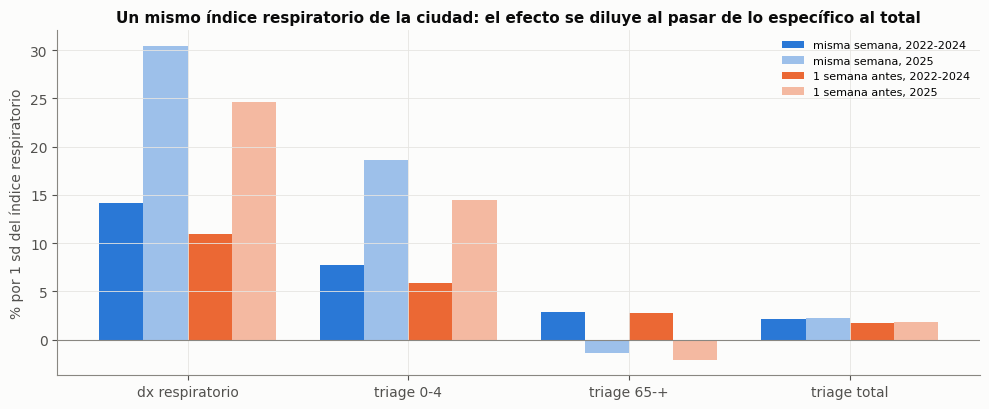

misma semana                                                             1 semana antes                                                            
                    efecto %      p efecto % 2025 sin estación: efecto % sin estación: p       efecto %      p efecto % 2025 sin estación: efecto % sin estación: p
desenlace                                                                                                                                                          
dx respiratorio       14.207  0.000        30.440                  4.132           0.149         10.984  0.000        24.593                  1.610           0.524
triage 0-4             7.748  0.001        18.577                  3.129           0.023          5.917  0.011        14.477                  1.832           0.229
triage 65-+            2.855  0.002        -1.346                  0.638           0.424          2.778  0.000        -2.073                  0.498           0.469
triage total           2.186  0.003         2.266                  0.375           0.497          1.684  0.029         1.774                 -0.049           0.929

In [26]:
# La misma ola respiratoria, vista desde cada desenlace: de lo específico a lo general
orden = ["dx respiratorio", "triage 0-4", "triage 65-+", "triage total"]
g1 = FAMS[(FAMS.familia == "respiratoria") & (FAMS.rezago == 1)].set_index("desenlace").loc[orden]
g0 = FAMS[(FAMS.familia == "respiratoria") & (FAMS.rezago == 0)].set_index("desenlace").loc[orden]
fig, ax = plt.subplots(figsize=(10, 4.2)); x = np.arange(len(orden)); w = .2
ax.bar(x - 1.5 * w, g0["efecto %"], w, color=AZUL, label="misma semana, 2022-2024")
ax.bar(x - .5 * w, g0["efecto % 2025"], w, color=AZUL, alpha=.45, label="misma semana, 2025")
ax.bar(x + .5 * w, g1["efecto %"], w, color=NARANJA, label="1 semana antes, 2022-2024")
ax.bar(x + 1.5 * w, g1["efecto % 2025"], w, color=NARANJA, alpha=.45, label="1 semana antes, 2025")
ax.set_xticks(x, orden); ax.axhline(0, color=MUDO, lw=.8); ax.set_ylabel("% por 1 sd del índice respiratorio"); ax.legend(fontsize=8)
ax.set_title("Un mismo índice respiratorio de la ciudad: el efecto se diluye al pasar de lo específico al total")
plt.tight_layout(); plt.show()
pd.concat({"misma semana": g0[["efecto %", "p", "efecto % 2025", "sin estación: efecto %", "sin estación: p"]],
           "1 semana antes": g1[["efecto %", "p", "efecto % 2025", "sin estación: efecto %", "sin estación: p"]]}, axis=1).round(3)

## Lectura de la dilución

Es el mismo índice respiratorio de la ciudad visto desde cuatro desenlaces, de más específico a más general. A rezago 0, el efecto en descubrir es de **+14,2 % en los diagnósticos respiratorios, +7,7 % en el triage de 0 a 4, +2,9 % en el de 65 o más y +2,2 % en el total**. A una semana de adelanto baja a +11,0, +5,9, +2,8 y +1,7 %. En 2025 la misma escalera es de +30,4, +18,6, −1,3 y +2,3 % a rezago 0.

**El gradiente es el esperable de un factor que actúa sobre una parte del hospital.** Cuanto más amplio es el desenlace, menor es el efecto. Los diagnósticos respiratorios fueron entre el 2,0 y el 4,1 % del triage en 2022-2025: por dilución pura, un +14,2 % en ellos produciría menos de +0,6 % en el total, y el total sube +2,2 %. Esa diferencia indica que parte del efecto sobre el total no pasa por los diagnósticos respiratorios codificados, o que es estación compartida entre el índice y el total.

**Cautela.** Los efectos de 2025 son sistemáticamente más grandes que los de descubrir. Con 52 semanas y un índice que tuvo una sola ola breve ese año, el tamaño exacto no se debe usar.

---
# 10. Conclusiones y límites

## Qué cambió al volver a medir

La primera medición, contra el triage total, concluyó que nada de la vigilancia entraba al repertorio. La repetición con mecanismos corrige el alcance de esa conclusión, no su fondo:

| Diseño | Pruebas | Sobreviven a BH | Confirmadas en 2025 | Resisten estación y rezagos negativos |
|---|---|---|---|---|
| Barrido de 59 series de Manizales y Caldas contra el total | 531 | 10 con rezago de 1 o más (5 series) | 3 (EDA hospitalizados de Caldas, 4 a 6 semanas) | **0** |
| Componentes de presión epidemiológica × 4 desenlaces | 144 | 8 con rezago de 1 o más | 1 (PC3 → respiratorio, 5 semanas) | **0** |
| Geografías contra el total (exploratorio) | 48 | 0 | — | — |
| Bandas de edad de IRA y EDA contra su banda del triage | 90 | 6 | 3 (IRA 0-4 en rezagos 0 y 1; IRA 5-19 en rezago 0) | Estación sí en 2025; dirección no |
| Familias contra desenlaces específicos, con mecanismo | 70 | 11 | — | **0** sin estación |

## Qué se sostiene

1. **Contra el triage total, ninguna serie de vigilancia anticipa el volumen de forma separable del calendario y de la estación.** Lo único confirmado en el barrido (EDA hospitalizados de Caldas) acompaña a la estación, y el índice de PC3 que se confirma no tiene mecanismo.
2. **El factor actúa por edad, y en las edades infantil y escolar con un tamaño que el total no deja ver.** La IRA de Manizales de 0 a 4 años y el triage de 0 a 4 tienen r = 0,703 en conteos y 0,808 con cada año contra su media; en 2022-2024 el efecto es de +9,2 % por desviación típica a rezago 0 y de +7,3 % a una semana, y se repite en 2025 incluso con el desenlace sin estación. En 5 a 14 años, +7,5 %.
3. **El efecto se diluye en el total de forma calculable.** El triage de 0 a 4 años es el 3,2 % del total y el de 5 a 14 el 4,8 %. El mismo índice respiratorio da +14,2 % en los diagnósticos respiratorios, +7,7 % en el triage de 0 a 4 y +2,2 % en el total.
4. **Las olas respiratorias son pocas.** Hubo dos largas (mayo de 2022 y mayo de 2024), ninguna en 2023 y casi ninguna en 2025. Los años recientes tienen pocos episodios para aprender de ellos.
5. **Los eventos individuales con fuga** (suicidio, violencias, intoxicaciones, agresiones, materna) son desenlaces y no predictores. El dengue casi no existe en Manizales (5, 84 y 4 casos en 2023, 2024 y 2025).

## Qué no se puede afirmar

- **Que la ciudad avise al hospital con semanas de adelanto.** El triage infantil predice la IRA infantil dos semanas después tan bien como al revés (+25,2 % frente a +26,4 %): las series se mueven juntas, y la autocorrelación de las anomalías impide ordenarlas.
- **Que el efecto de las olas respiratorias sea distinto del de la estación.** Las dos olas largas caen en la misma época (mayo) y el ajuste estacional con tres años de descubrir absorbe parte del efecto. Con el desenlace sin estación no sobrevive nada en el diseño por episodios ni en el de familias. Es un caso de «no se puede separar de la fecha» y no de «no afecta».
- **Que la IRA de los mayores, la gastro, la salud mental o la violencia no actúen.** Se midieron con pocos casos por semana y, en lo que sobrevivió, el signo se invirtió en 2025.

## Qué queda como candidato

El **índice respiratorio de la ciudad por banda de edad**, con la IRA de 0 a 4 y de 5 a 19 años como núcleo, para el triage de esas edades y para el desenlace respiratorio del hospital. Tiene mecanismo (contagio comunitario, luego consulta), se repite en 2025 con signo y tamaño, y se puede calcular a tiempo con Power BI (rezago de 2 a 3 semanas, nivel un 4 a 8 % mayor que el de los microdatos). El resto de Caldas se adelanta una semana a la IRA de Manizales (p = 0,009, sin corrección por pruebas múltiples).

## Límites de todo el cuaderno

- **Poca potencia en la confirmación.** Un año de 52 semanas no confirma efectos reales de ~1,5 % por desviación típica; los de las bandas infantiles son mucho mayores y sí se detectan.
- **Pocos episodios.** Con 5 olas respiratorias, 2 de ellas largas, no hay estimaciones por episodio.
- **Rezago 0 no operativo.** Lo más fuerte ocurre en la misma semana, que no está disponible al pronosticar.
- **La anomalía de las secciones 2 a 5 usa la media del año entero**, que en operación no existe; las secciones 7 a 9 usan la versión operativa, que correlaciona 0,806 con aquella.
- **El desenlace conserva la estacionalidad a propósito.** Una serie con la estación mal quitada parece predictora, que es justo lo que pasó con la EDA hospitalizada.
- **Los desenlaces específicos** (diagnósticos y banda de edad) se apoyan en agregados semanales y en una codificación que puede haber cambiado entre años.
- **Errores de la fuente.** La SE53 de 2025 del 998 multiplica por ~7 la EDA de Manizales y se anuló en memoria, no en el archivo de origen.